Все ссылки на ИИ:

### 1. Три основные модели для анализа тональности

1\. RuBERT-tiny balanced — лучшая по Macro-F1 (0,455).\
[Hugging Face — cointegrated/rubert-tiny-sentiment-balanced](https://huggingface.co/cointegrated/rubert-tiny-sentiment-balanced)

2\. RuBERT-tiny2 — второе место (0,447).\
[Hugging Face — seara/rubert-tiny2-russian-sentiment](https://huggingface.co/seara/rubert-tiny2-russian-sentiment)

3\. RuBERT-base / RuSentiment — третье место (0,437).\
[Hugging Face — blanchefort/rubert-base-cased-sentiment-rusentiment](https://huggingface.co/blanchefort/rubert-base-cased-sentiment-rusentiment)

### 2. Дополнительные модели

4\. Qwen2.5-0.5B-Instruct — первоначальные эксперименты с русскими отзывами и переводом.\
[Hugging Face — Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct?utm_source=chatgpt.com)

5\. Helsinki-NLP OPUS-MT — перевод текстов с русского на английский, добавленный в последнюю версию ноутбука.\
[Hugging Face — opus-mt-ru-en](https://huggingface.co/Helsinki-NLP/opus-mt-ru-en?utm_source=chatgpt.com)

6\. XLM-RoBERTa Sentiment — дополнительная модель для сравнения тональности русского текста и английского перевода.\
[Hugging Face — twitter-xlm-roberta-base-sentiment](https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base-sentiment?utm_source=chatgpt.com)

Важно: первые три модели действительно прошли проверку на всех 7 540 отзывах. Qwen ранее тестировался на 150 отзывах. Для Helsinki-NLP и XLM-RoBERTa код подготовлен, но подтверждённых результатов их полного запуска у нас пока нет.



# Тональность банковских отзывов — три модели


### Что будет рассчитано
- Одни и те же **1 000 отзывов** для трёх готовых моделей.
- Затем **все строки исходного файла** (7 540); результаты пилота используются повторно.
- Accuracy, **Macro-F1**, balanced accuracy, precision/recall/F1 каждого класса, матрицы ошибок и сравнение с правилом «всегда негатив».
- Дополнительно: один сохранённый перевод RU→EN и сравнение одной и той же XLM-R на оригинале и переводе. По умолчанию это те же 1 000 строк; `english_scope="full"` включает весь файл.



In [ ]:
import sys
import platform
from pathlib import Path

if sys.version_info < (3, 10):
    raise RuntimeError("Нужен Python 3.10 или новее. В Colab выберите среду Python 3.")

print("Блокнот открыт; код Python выполняется.")
print("Python:", platform.python_version())
print("Рабочая папка:", Path.cwd())
print("Следующая кодовая ячейка установит необходимые библиотеки.")


Блокнот открыт; код Python выполняется.
Python: 3.13.18
Рабочая папка: /content
Следующая кодовая ячейка установит необходимые библиотеки.


## 1. План исследования и правила сравнения

1. Проверить источник, SHA-256, количество строк, пропуски, рейтинги, повторы и конфликтующие метки.
2. Получить proxy-метки: **1–2 звезды — негатив; 3 — условно нейтрально; 4–5 — позитив**. Три звезды могут означать смешанный или отрицательный текст: это ограничение разметки, а не доказанная ошибка модели.
3. Зафиксировать случайную выборку 1 000 строк с исходными долями классов. Для всех моделей она одна и та же.
4. Применить три готовые нейросети. Вход — только заголовок и отзыв; рейтинг, имя автора и ответ разработчика не передаются.
5. Сравнить модели на 1 000 строках, затем на всём файле. Параметры между этапами не подбирать. Полный корпус включает пилот: это не два независимых теста.
6. Построить матрицы ошибок, F1 по классам, сравнение с baseline, парные интервалы разницы Macro-F1 и диагностику на уникальных текстах.
7. Дополнительно: перевести тексты один раз, сохранить переводы и сравнить **одну и ту же XLM-R** на русском и английском. Так различие не смешивается со сменой классификатора.
8. Прочитать реальные ошибки, связать выводы с числами и примерами. Согласовать выбранные данные с преподавателем.




## 2. Какие модели сравниваются

| Роль | Модель | Почему она здесь |
|---|---|---|
| Основная 1 | `cointegrated/rubert-tiny-sentiment-balanced` | Небольшой готовый классификатор коротких русских текстов, 3 класса |
| Основная 2 | `seara/rubert-tiny2-russian-sentiment` | Другая дообученная версия RuBERT-tiny2, 3 класса |
| Основная 3 | `blanchefort/rubert-base-cased-sentiment-rusentiment` | Более крупная модель, обученная на RuSentiment |
| Переводчик, не участник рейтинга тональности | `Helsinki-NLP/opus-mt-ru-en` | Специализированная RU→EN-модель; перевод сохраняется один раз |
| Дополнительный парный эксперимент | `cardiffnlp/twitter-xlm-roberta-base-sentiment` | Один многоязычный классификатор для RU и EN |

У XLM-R дообучение тональности проводилось на восьми языках, без русского, поэтому RU — перенос на другой язык. Это заранее известное ограничение, а не гарантия превосходства перевода.



## 3. Метрики — фиксируем до запуска

Основная метрика — Macro-F1:

\[
F1_c=\frac{2TP_c}{2TP_c+FP_c+FN_c},\qquad
MacroF1=\frac{F1_{negative}+F1_{neutral}+F1_{positive}}{3}.
\]

Каждый класс имеет одинаковый вес. Если модель совсем не выдаёт нейтральный класс, его F1 равен нулю; класс не исключается из среднего.

| Что считаем | Зачем |
|---|---|
| **Macro-F1** | Главная мера сравнения трёх классов при дисбалансе |
| **Precision / recall / F1 / support каждого класса** | Проверить, какие отзывы теряются и какие ложные срабатывания появляются |
| **Balanced accuracy = среднее recall трёх классов** | Оценить полноту распознавания независимо от частоты классов |
| **Accuracy** | Понятная доля совпадений, но не основная метрика |
| **Матрица ошибок** | Увидеть, какие именно классы путаются |
| **Время и число новых / кешированных текстов** | Не смешивать скорость вычислений с повторным чтением готовых ответов |

**Baseline:** заранее фиксированное правило «всегда негатив». Это не обученная нейросеть. Скорости разных устройств не сравниваются как свойство самой модели. Оценки уверенности не считаются калиброванными вероятностями правильности.

**Не используем:** бинарный ROC-AUC без обоснования для трёх классов; BLEU без эталонных переводов; «процент правильных переводов» по наличию кириллицы.

Парный кластерный bootstrap: 500 повторов, одинаковые нормализованные тексты выбираются вместе. Интервал разницы Macro-F1 показывает чувствительность к ресемплингу этого корпуса. Это не погрешность уже посчитанного полного файла и не гарантия качества на будущих данных. Сравнения разведочные, без заявлений о доказанной причинности или универсальном победителе.


## 4. Установка зависимостей

Используется PyTorch, а не платный API. Уже установленный подходящий PyTorch не заменяется, чтобы не ломать CUDA в Colab. Transformers зафиксирован. В чистом локальном окружении при отсутствии PyTorch ставится CPU-вариант. Перезапустите ядро перед первым запуском, если ранее использовались другие версии библиотек.


In [ ]:
import os
import sys
import subprocess
import importlib.util
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 10):
    raise RuntimeError("Нужен Python 3.10 или новее.")

os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
os.environ["HF_HUB_ETAG_TIMEOUT"] = "30"
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"

if importlib.util.find_spec("packaging") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "packaging"])
from packaging.requirements import Requirement
from packaging.version import Version

requirements = [
    "transformers==4.57.6", "huggingface-hub>=0.34,<1", "pandas>=2.1,<3",
    "numpy>=1.26,<3", "scikit-learn>=1.5,<2", "matplotlib>=3.8,<4",
    "sentencepiece>=0.2,<0.3", "sacremoses>=0.1,<0.2", "tqdm>=4.66,<5",
    "kagglehub>=0.3.13,<1",
]
needed = []
for requirement in requirements:
    spec = Requirement(requirement)
    try:
        installed = version(spec.name)
    except PackageNotFoundError:
        installed = None
    if installed is None or not spec.specifier.contains(installed):
        needed.append(requirement)
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *needed])

try:
    torch_version = version("torch")
except PackageNotFoundError:
    torch_version = None
if torch_version is None or Version(torch_version.split("+")[0]) < Version("2.6"):
    command = [sys.executable, "-m", "pip", "install", "torch>=2.6,<3"]
    if sys.platform != "darwin":
        command += ["--index-url", "https://download.pytorch.org/whl/cpu"]
    subprocess.check_call(command)

print("Зависимости готовы. API-ключи и платёжные данные не требуются.")


Зависимости готовы. API-ключи и платёжные данные не требуются.


## 5. Общие настройки

`run_full=True` означает весь CSV после пилота. `run_english=True` запускает дополнительную ветку. Английский эксперимент по умолчанию использует **те же 1 000 строк**, не весь корпус; для полного перевода можно задать `english_scope="full"`.

> Если Colab удалит виртуальную машину, файлы на её временном диске исчезнут. Для продолжения скачайте каталог результатов или используйте заранее подключённый постоянный каталог как `output_dir`. Ноутбук сам не подключает аккаунты и диски.


In [ ]:
import gc
import hashlib
import json
import math
import os
import platform
import re
import shutil
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split

LABELS = ["negative", "neutral", "positive"]
PRED_LABELS = LABELS + ["invalid"]
LABEL_RU = {"negative": "Негатив", "neutral": "Нейтрально", "positive": "Позитив"}
CODE_VERSION = "sentiment-benchmark-5.0"
ORIGINAL_SHA256 = "91aacb2f65facd1e818c97086648e4d501a414923f7d456c86e6123b681fba5b"

@dataclass(frozen=True)
class Settings:
    """Настройки эксперимента; менять их нужно ДО просмотра итоговых метрик."""
    data_file: str = "sber_app.csv"
    output_dir: str = "sentiment_results"
    kaggle_handle: str = "kicelevalexey/bank-app-reviews-rus"
    expected_rows: int = 7540
    require_original_hash: bool = True
    pilot_size: int = 1000
    run_full: bool = True
    # Английская ветка — отдельный, более долгий дополнительный эксперимент.
    run_english: bool = True
    english_scope: str = "pilot"  # "pilot" = те же 1000 строк; "full" = весь файл.
    seed: int = 42
    max_input_tokens: int = 512
    document_batch_size: int = 32
    cpu_batch_size: int = 8
    gpu_batch_size: int = 16
    bootstrap_repeats: int = 500
    translator_chunk_tokens: int = 448
    translation_max_new_tokens: int = 480
    translation_beams: int = 4
    allow_colab_upload: bool = True

@dataclass(frozen=True)
class ModelSpec:
    key: str
    repo: str
    name: str
    activation: str = "softmax"
    twitter_preprocess: bool = False

# Три разные готовые нейросети. Порядок классов берём из config.id2label.
CORE_MODELS = [
    ModelSpec("tiny", "cointegrated/rubert-tiny-sentiment-balanced", "RuBERT-tiny balanced", "sigmoid"),
    ModelSpec("tiny2", "seara/rubert-tiny2-russian-sentiment", "RuBERT-tiny2"),
    ModelSpec("base", "blanchefort/rubert-base-cased-sentiment-rusentiment", "RuBERT-base / RuSentiment"),
]
MULTILINGUAL = ModelSpec("xlmr", "cardiffnlp/twitter-xlm-roberta-base-sentiment", "XLM-R sentiment", "softmax", True)
TRANSLATOR = "Helsinki-NLP/opus-mt-ru-en"


In [ ]:
# Изменять только нужные настройки ДО начала эксперимента.
CFG = Settings(
    data_file="sber_app.csv",
    output_dir="sentiment_results",
    pilot_size=1000,
    run_full=True,
    run_english=True,
    english_scope="pilot",  # Поменять на "full" для перевода всего файла.
)
print(CFG)


Settings(data_file='sber_app.csv', output_dir='sentiment_results', kaggle_handle='kicelevalexey/bank-app-reviews-rus', expected_rows=7540, require_original_hash=True, pilot_size=1000, run_full=True, run_english=True, english_scope='pilot', seed=42, max_input_tokens=512, document_batch_size=32, cpu_batch_size=8, gpu_batch_size=16, bootstrap_repeats=500, translator_chunk_tokens=448, translation_max_new_tokens=480, translation_beams=4, allow_colab_upload=True)


## 6. Проверяемые вспомогательные функции

Эти ячейки определяют функции, но ещё не запускают модели. Здесь видны загрузка, проверка метрик и механизм восстановления после прерывания.


### 6.1. Данные, сопоставление меток и независимая проверка Macro-F1

Дубликаты не удаляются из полного результата. Неисправные рейтинги/пустые тексты останавливают работу с понятным сообщением. Это предотвращает незаметное уменьшение знаменателя ради роста качества.


In [ ]:
def sha_text(text: str) -> str:
    """Отпечаток текста: нужен для повторного использования того же предсказания."""
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def json_digest(value: Any) -> str:
    return sha_text(json.dumps(value, ensure_ascii=False, sort_keys=True, allow_nan=False))


def atomic_json(path: Path, value: Any) -> None:
    """Пишем сначала временный файл, затем заменяем основной целиком."""
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    tmp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(tmp, path)


def atomic_csv(path: Path, frame: pd.DataFrame) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    frame.to_csv(tmp, index=False, encoding="utf-8-sig")
    os.replace(tmp, path)


def locate_csv(cfg: Settings) -> Path:
    """Сначала локальный CSV; затем официальный клиент Kaggle; затем загрузка в Colab.

    Нет зависимости от старой прямой ссылки, дававшей HTTP 404. Новый файл другого
    содержания не подменяется незаметно: отдельная функция проверяет его SHA-256.
    """
    chosen = Path(cfg.data_file).expanduser()
    candidates = [chosen, Path.cwd() / chosen.name,
                  Path.cwd() / "data" / chosen.name, Path("/content") / chosen.name]
    for candidate in candidates:
        if candidate.is_file():
            return candidate.resolve()
    download_error = ""
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(cfg.kaggle_handle))
        matches = list(folder.rglob(chosen.name))
        if len(matches) == 1:
            return matches[0].resolve()
        download_error = f"В архиве найдено {len(matches)} файлов с именем {chosen.name}."
    except Exception as exc:
        download_error = f"{type(exc).__name__}: {str(exc)[:300]}"
    print("Автозагрузка Kaggle не удалась:", download_error)
    if cfg.allow_colab_upload:
        try:
            from google.colab import files
        except ImportError:
            pass
        else:
            print("Выберите свой исходный sber_app.csv. Никаких API-ключей вводить не нужно.")
            uploaded = files.upload()
            names = [n for n in uploaded if Path(n).name == chosen.name]
            if len(names) == 1:
                target = Path.cwd() / chosen.name
                target.write_bytes(uploaded[names[0]])
                return target.resolve()
    raise FileNotFoundError(
        f"Исходный {chosen.name} отсутствует. Положите его рядом с ноутбуком "
        "или задайте полный путь в Settings.data_file. Данные не заменялись другим набором."
    )


def prepare_frame(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """Проверяем исходные строки, сохраняя каждую; готовим только текст и proxy-метку."""
    missing = {"review", "rating"} - set(raw.columns)
    if missing:
        raise ValueError(f"Не хватает столбцов: {sorted(missing)}")
    frame = pd.DataFrame({"source_row": np.arange(len(raw), dtype=int)})
    frame["title"] = raw["title"].fillna("").astype(str).str.strip().to_numpy() if "title" in raw else ""
    frame["review"] = raw["review"].fillna("").astype(str).str.strip().to_numpy()
    rating = pd.to_numeric(raw["rating"], errors="coerce").reset_index(drop=True)
    valid_rating = rating.isin([1, 2, 3, 4, 5])
    if not valid_rating.all():
        raise ValueError(f"Некорректный рейтинг в строках {frame.loc[~valid_rating, 'source_row'].head(10).tolist()}; строки не удалены.")
    frame["rating"] = rating.astype(int)
    frame["text"] = (frame.title + "\n" + frame.review).str.strip()
    if frame.text.eq("").any():
        raise ValueError("Есть строки без текста и заголовка. Нужна проверка, а не молчаливое удаление.")
    frame["expected"] = frame.rating.map({1: "negative", 2: "negative", 3: "neutral", 4: "positive", 5: "positive"})
    frame["text_sha256"] = frame.text.map(sha_text)
    frame["group_sha256"] = frame.text.str.replace(r"\s+", " ", regex=True).str.casefold().map(sha_text)
    frame["characters"] = frame.text.str.len()
    groups = frame.groupby("group_sha256", sort=False)
    conflicting = groups.expected.nunique().gt(1)
    audit = {
        "rows": int(len(frame)), "unique_exact_texts": int(frame.text_sha256.nunique()),
        "duplicate_exact_rows": int(frame.text_sha256.duplicated().sum()),
        "normalized_groups": int(frame.group_sha256.nunique()),
        "groups_with_conflicting_labels": int(conflicting.sum()),
        "class_counts": {k: int(v) for k, v in frame.expected.value_counts().items()},
        "rating_counts": {str(k): int(v) for k, v in frame.rating.value_counts().sort_index().items()},
        "rows_dropped": 0,
    }
    if set(frame.expected) != set(LABELS):
        raise ValueError("В исходном файле должны присутствовать все три класса.")
    return frame, audit


def load_data(cfg: Settings) -> tuple[pd.DataFrame, dict]:
    path = locate_csv(cfg)
    blob = path.read_bytes()
    digest = hashlib.sha256(blob).hexdigest()
    if cfg.require_original_hash and digest != ORIGINAL_SHA256:
        raise ValueError(
            "SHA-256 отличается от исходного файла предыдущей работы. "
            "Проверьте, что это тот же набор. Для намеренно другой версии явно задайте "
            "require_original_hash=False и корректное expected_rows."
        )
    frame, audit = prepare_frame(pd.read_csv(path, encoding="utf-8-sig"))
    if len(frame) != cfg.expected_rows:
        raise ValueError(f"Ожидалось {cfg.expected_rows} строк, получено {len(frame)}. Состав данных нужно согласовать.")
    audit.update({"source_path": str(path), "dataset_sha256": digest,
                  "matches_previous_file": digest == ORIGINAL_SHA256,
                  "kaggle_handle": cfg.kaggle_handle})
    return frame, audit


def choose_pilot(frame: pd.DataFrame, n: int, seed: int) -> pd.DataFrame:
    """Общая для всех моделей случайная выборка с сохранением пропорций классов.

    Это этап диагностики, НЕ отдельный независимый тест после настройки.
    Полный набор включает пилот. Модели на этом наборе не обучаются.
    """
    if n < 1000:
        raise ValueError("Для этой работы минимальный пилот — 1000 строк.")
    if n > len(frame):
        raise ValueError("Размер пилота больше исходного набора.")
    if n == len(frame):
        return frame.copy()
    _, selected = train_test_split(np.arange(len(frame)), test_size=n,
                                   stratify=frame.expected, random_state=seed)
    return frame.iloc[np.sort(selected)].copy().reset_index(drop=True)


def metric_bundle(expected, predicted) -> dict:
    """Считаем качество; invalid считается ошибкой и не выбрасывается из знаменателя."""
    true = np.asarray(expected, dtype=str)
    pred = np.asarray(predicted, dtype=str)
    if len(true) == 0 or len(true) != len(pred):
        raise ValueError("Пустые или разной длины списки меток.")
    if not set(true) <= set(LABELS) or not set(pred) <= set(PRED_LABELS):
        raise ValueError("Неизвестные метки; их нельзя незаметно превратить в нейтральные.")
    if set(true) != set(LABELS):
        raise ValueError("В оценке должны присутствовать все три класса.")
    report = classification_report(true, pred, labels=LABELS, output_dict=True, zero_division=0)
    cm = np.zeros((3, 4), dtype=int)
    for actual, answer in zip(true, pred):
        cm[LABELS.index(actual), PRED_LABELS.index(answer)] += 1
    # Независимая проверка Macro-F1 по TP / FP / FN.
    tp = np.diag(cm[:, :3]).astype(float)
    denominator = cm.sum(axis=1) + cm[:, :3].sum(axis=0)
    manual_f1 = np.divide(2 * tp, denominator, out=np.zeros(3), where=denominator != 0).mean()
    macro = f1_score(true, pred, labels=LABELS, average="macro", zero_division=0)
    if not math.isclose(float(macro), float(manual_f1), abs_tol=1e-12):
        raise AssertionError("Независимая проверка Macro-F1 не совпала со sklearn.")
    return {"n": int(len(true)), "accuracy": float(accuracy_score(true, pred)),
            "macro_f1": float(macro),
            "balanced_accuracy": float(np.mean([report[k]["recall"] for k in LABELS])),
            "invalid_count": int(np.sum(pred == "invalid")),
            "per_class": {k: report[k] for k in LABELS}, "confusion_matrix": cm.tolist()}


def canonical_order(id2label: dict) -> list[int]:
    """Номера классов различаются у моделей: проверяем явные имена из конфигурации."""
    mapping = {int(i): str(label).strip().lower() for i, label in id2label.items()}
    if len(mapping) != 3 or set(mapping.values()) != set(LABELS):
        raise ValueError(f"Неожиданный id2label={mapping}. Нужна проверка карточки модели.")
    return [next(i for i, label in mapping.items() if label == name) for name in LABELS]


def aggregate_chunks(scores: np.ndarray, owners: list[int], weights: list[int], n_docs: int) -> np.ndarray:
    """Среднее оценок частей, взвешенное по числу токенов; ни один токен не теряется."""
    scores = np.asarray(scores, dtype=float)
    if scores.shape != (len(owners), 3) or len(weights) != len(owners):
        raise ValueError("Размеры частей не совпадают.")
    if n_docs < 0 or any(not 0 <= owner < n_docs for owner in owners):
        raise ValueError("Некорректный номер документа для части текста.")
    if not np.isfinite(scores).all() or any(w <= 0 for w in weights):
        raise ValueError("Некорректные численные оценки частей.")
    result = np.zeros((n_docs, 3))
    total = np.zeros(n_docs)
    for row, owner, weight in zip(scores, owners, weights):
        result[owner] += row * weight
        total[owner] += weight
    return np.divide(result, total[:, None], out=np.zeros_like(result), where=total[:, None] != 0)


### 6.2. Кэш, точные ревизии моделей и среда

У каждой записи кэша есть отпечаток входного текста. Протокол включает модель, commit, версию кода, число токенов, способ объединения частей, числовой режим и библиотеку. При изменении протокола прежние ответы не подставляются. Повреждённая последняя запись пересчитывается; повреждение середины журнала считается ошибкой.


In [ ]:
class Journal:
    """Журнал завершённых текстов. Дописывается после каждой небольшой группы.

    Совместимость задаётся хешем протокола. Обрыв последней строки безопасно
    восстанавливается. Повреждение середины журнала не игнорируется.
    """
    def __init__(self, root: Path, protocol: dict):
        self.protocol = protocol
        self.folder = root / json_digest(protocol)[:20]
        self.folder.mkdir(parents=True, exist_ok=True)
        self.path = self.folder / "completed.jsonl"
        manifest = self.folder / "protocol.json"
        if manifest.exists() and json.loads(manifest.read_text()) != protocol:
            raise ValueError("Протокол кэша не совпадает.")
        atomic_json(manifest, protocol)
        self.records: dict[str, dict] = {}
        if self.path.exists():
            lines = self.path.read_bytes().splitlines(keepends=True)
            valid_bytes = 0
            for index, line in enumerate(lines):
                try:
                    record = json.loads(line)
                except (ValueError, UnicodeDecodeError):
                    if index != len(lines) - 1:
                        raise ValueError("Повреждение в середине журнала кэша.")
                    warnings.warn("Незавершённая последняя запись удалена; этот текст будет пересчитан.")
                    with self.path.open("r+b") as stream:
                        stream.truncate(valid_bytes)
                    break
                key = record.get("key")
                if not isinstance(key, str) or len(key) != 64:
                    raise ValueError("Некорректный ключ кэша.")
                if key in self.records and self.records[key] != record:
                    raise ValueError("В кэше конфликтующие ответы для одного входа.")
                self.records[key] = record
                valid_bytes += len(line)
            # Валидная последняя запись без '\n' тоже должна дописываться корректно.
            if self.path.stat().st_size and not self.path.read_bytes().endswith(b"\n"):
                with self.path.open("ab") as stream:
                    stream.write(b"\n")

    def append(self, records: list[dict]) -> None:
        fresh = []
        seen = dict(self.records)
        for record in records:
            key = record["key"]
            if key in seen:
                if seen[key] != record:
                    raise ValueError("Попытка перезаписать предсказание без смены протокола.")
            else:
                fresh.append(record)
                seen[key] = record
        if not fresh:
            return
        payload = "".join(json.dumps(r, ensure_ascii=False, allow_nan=False) + "\n" for r in fresh)
        with self.path.open("ab") as stream:
            stream.write(payload.encode("utf-8"))
            stream.flush()
            os.fsync(stream.fileno())
        for record in fresh:
            self.records[record["key"]] = record


def resolve_revision(repo: str, output_dir: Path) -> str:
    """Первый запуск фиксирует точный commit модели; повторные используют тот же."""
    path = output_dir / "model_revisions.json"
    saved = json.loads(path.read_text()) if path.exists() else {}
    if repo not in saved:
        from huggingface_hub import HfApi
        saved[repo] = HfApi().model_info(repo, token=False).sha
        atomic_json(path, saved)
    revision = saved[repo]
    if not re.fullmatch(r"[0-9a-f]{40}", revision):
        raise ValueError("Не удалось зафиксировать точную ревизию модели.")
    return revision


def environment_info() -> dict:
    packages = {}
    for name in ["torch", "transformers", "huggingface-hub", "pandas", "numpy", "scikit-learn", "sentencepiece"]:
        try:
            packages[name] = version(name)
        except PackageNotFoundError:
            packages[name] = None
    return {"python": platform.python_version(), "platform": platform.platform(), "packages": packages}


def runtime_info() -> tuple[Any, str]:
    """Используем GPU, если он уже доступен. Никакие платные ресурсы не подключаем."""
    import torch
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        torch.set_num_threads(min(4, os.cpu_count() or 1))
    torch.manual_seed(42)
    return torch, device


def make_protocol(spec: ModelSpec, revision: str, cfg: Settings, dataset_sha: str, device: str) -> dict:
    return {"code": CODE_VERSION, "task": "classification", "model": asdict(spec),
            "revision": revision, "dataset_sha256": dataset_sha,
            "max_input_tokens": cfg.max_input_tokens,
            "aggregation": "nonoverlapping_token_weighted_mean", "dtype": "float32",
            "device_type": device,
            "transformers": environment_info()["packages"]["transformers"],
            "torch": environment_info()["packages"]["torch"]}


### 6.3. Использование нейросеть

В `Classifier._forward()` вызывается **`self.model(**batch).logits`** — это реальный проход скачанной нейросети. Результат определяется оценками модели, а не звёздами и не словарём ключевых слов.

Контекст конечен: длинный отзыв делится на неперекрывающиеся части, все токены сохраняются. Оценки частей усредняются с весом по числу токенов. Это заранее выбранное правило, а не полноценное понимание всех частей одновременно; например, противопоставление между частями может потеряться. Число частей сохраняется для каждого текста.

Для cointegrated применён sigmoid из авторского примера; для остальных — softmax. Поэтому значения `score_*` разных моделей нельзя напрямую сравнивать как одинаково калиброванные вероятности. Выбор класса и метрики остаются сопоставимыми.


In [ ]:
class Classifier:
    """Настоящий инференс Hugging Face / PyTorch, без облачного inference API."""
    def __init__(self, spec: ModelSpec, revision: str, cfg: Settings):
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        self.torch, self.device = runtime_info()
        self.spec, self.cfg = spec, cfg
        self.tokenizer = AutoTokenizer.from_pretrained(spec.repo, revision=revision,
                                                       token=False, trust_remote_code=False)
        # float32 выбран для одинакового режима чисел на CPU и CUDA.
        self.model = AutoModelForSequenceClassification.from_pretrained(
            spec.repo, revision=revision, token=False, trust_remote_code=False,
            torch_dtype=self.torch.float32,
        ).to(self.device).eval()
        self.order = canonical_order(self.model.config.id2label)
        limit = min(cfg.max_input_tokens, int(self.model.config.max_position_embeddings))
        self.content_limit = limit - self.tokenizer.num_special_tokens_to_add(pair=False)
        if self.content_limit < 8:
            raise ValueError("Слишком короткий допустимый контекст.")
        self.batch_size = cfg.gpu_batch_size if self.device == "cuda" else cfg.cpu_batch_size

    def _forward(self, features: list[dict]) -> np.ndarray:
        batch = self.tokenizer.pad(features, padding=True, return_tensors="pt").to(self.device)
        try:
            with self.torch.inference_mode():
                logits = self.model(**batch).logits.float()
                # У cointegrated в авторском примере sigmoid; остальные — softmax.
                scores = logits.sigmoid() if self.spec.activation == "sigmoid" else logits.softmax(dim=-1)
                result = scores[:, self.order].cpu().numpy()
            return result
        except self.torch.cuda.OutOfMemoryError:
            # Уменьшаем батч, а не заменяем ответ выдуманным классом.
            del batch
            self.torch.cuda.empty_cache()
            if len(features) == 1:
                raise
            middle = len(features) // 2
            return np.concatenate([self._forward(features[:middle]), self._forward(features[middle:])])

    def predict(self, texts: list[str]) -> list[dict]:
        features, owners, weights = [], [], []
        n_tokens, n_chunks = [], []
        for owner, text in enumerate(texts):
            if self.spec.twitter_preprocess:
                # Та же нормализация для RU и EN у XLM-R; содержание оценки не меняем.
                text = re.sub(r"https?://\S+", "http", text)
                text = re.sub(r"(?<!\w)@\w+", "@user", text)
            ids = self.tokenizer.encode(text, add_special_tokens=False, truncation=False, verbose=False) if text.strip() else []
            n_tokens.append(len(ids))
            parts = [ids[i:i+self.content_limit] for i in range(0, len(ids), self.content_limit)]
            n_chunks.append(len(parts))
            for part in parts:
                feature = self.tokenizer.prepare_for_model(
                    part, add_special_tokens=True, truncation=False,
                    return_attention_mask=True, return_token_type_ids="token_type_ids" in self.tokenizer.model_input_names,
                )
                features.append(dict(feature))
                owners.append(owner)
                weights.append(len(part))
        scores = np.empty((len(features), 3), dtype=float)
        # Группировка по длине уменьшает число добавленных pad-токенов.
        sorted_ids = sorted(range(len(features)), key=lambda i: len(features[i]["input_ids"]))
        for start in range(0, len(sorted_ids), self.batch_size):
            selected = sorted_ids[start:start+self.batch_size]
            scores[selected] = self._forward([features[i] for i in selected])
        averaged = aggregate_chunks(scores, owners, weights, len(texts))
        results = []
        for index, values in enumerate(averaged):
            if n_tokens[index] == 0:
                # Например, перевод оказался пустым. Это ошибка, а не «нейтрально».
                label = "invalid"
            else:
                label = LABELS[int(np.argmax(values))]
            results.append({"predicted": label, "n_tokens": n_tokens[index], "n_chunks": n_chunks[index],
                            **{f"score_{label}": float(values[i]) for i, label in enumerate(LABELS)}})
        return results

    def close(self) -> None:
        del self.model
        gc.collect()
        if self.device == "cuda":
            self.torch.cuda.empty_cache()


def classify_cached(frame: pd.DataFrame, text_column: str, spec: ModelSpec,
                    cfg: Settings, audit: dict) -> tuple[pd.DataFrame, dict]:
    """Считаем недостающие тексты и возвращаем ответ для КАЖДОЙ исходной строки."""
    root = Path(cfg.output_dir)
    revision = resolve_revision(spec.repo, root)
    _, device = runtime_info()
    protocol = make_protocol(spec, revision, cfg, audit["dataset_sha256"], device)
    journal = Journal(root / "cache", protocol)
    input_text = frame[text_column].fillna("").astype(str)
    keys = input_text.map(sha_text)
    unique = pd.DataFrame({"key": keys, "input": input_text}).drop_duplicates("key")
    missing = unique.loc[~unique.key.isin(journal.records)]
    engine = None
    started = time.perf_counter()
    load_seconds, inference_seconds = 0.0, 0.0
    try:
        if len(missing):
            begin = time.perf_counter()
            engine = Classifier(spec, revision, cfg)
            load_seconds = time.perf_counter() - begin
            from tqdm.auto import tqdm
            batches = range(0, len(missing), cfg.document_batch_size)
            for start in tqdm(batches, desc=spec.name, unit="группа"):
                group = missing.iloc[start:start+cfg.document_batch_size]
                begin = time.perf_counter()
                answers = engine.predict(group.input.tolist())
                spent = time.perf_counter() - begin
                inference_seconds += spent
                if len(answers) != len(group):
                    raise AssertionError("Количество ответов не совпало с количеством входов.")
                records = []
                for key, answer in zip(group.key, answers):
                    if answer["predicted"] not in PRED_LABELS:
                        raise ValueError("Неизвестный класс в ответе модели.")
                    records.append({"key": key, **answer, "batch_seconds_share": spent / len(group)})
                journal.append(records)
    finally:
        if engine is not None:
            engine.close()
    # Здесь не join по индексу после сортировки: явно сопоставляем текстовый ключ.
    predictions = pd.DataFrame([journal.records[key] for key in keys]).reset_index(drop=True)
    result = frame.reset_index(drop=True).copy()
    for col in ["predicted", "n_tokens", "n_chunks"] + [f"score_{k}" for k in LABELS]:
        result[col] = predictions[col].to_numpy()
    if not result.source_row.is_unique or len(result) != len(frame):
        raise AssertionError("Потеря или дублирование исходных строк.")
    timing = {"revision": revision, "device": device, "dtype": "float32",
              "new_unique_texts": int(len(missing)), "reused_unique_texts": int(len(unique)-len(missing)),
              "load_seconds_this_call": load_seconds, "inference_seconds_this_call": inference_seconds,
              "elapsed_seconds_this_call": time.perf_counter()-started,
              "unique_text_inference_seconds_in_cache": float(sum(journal.records[k]["batch_seconds_share"] for k in unique.key)),
              "note": "Время загрузки/скачивания отдельно; доля batch_seconds_share не является измерением отдельного отзыва."}
    return result, timing


### 6.4. Один перевод для повторного использования

Перевод не отправляется в облачный API: работает готовая Marian-модель внутри процесса. Переводы сохраняются в `translations.csv` и в совместимом кэше. Пустые переводы и достижение лимита отмечаются, а не исключаются из оценки. Кириллица в переводе — только диагностический флаг, а не доказательство ошибки.


In [ ]:
class Translator:
    """Специализированная RU→EN-модель. Один перевод можно использовать многократно."""
    def __init__(self, revision: str, cfg: Settings):
        from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
        self.cfg = cfg
        self.torch, self.device = runtime_info()
        self.tokenizer = AutoTokenizer.from_pretrained(TRANSLATOR, revision=revision, token=False, trust_remote_code=False)
        self.model = AutoModelForSeq2SeqLM.from_pretrained(
            TRANSLATOR, revision=revision, token=False, trust_remote_code=False,
            torch_dtype=self.torch.float32,
        ).to(self.device).eval()
        self.batch_size = 4 if self.device == "cuda" else 1
        self.max_new = min(cfg.translation_max_new_tokens, int(self.model.config.max_position_embeddings)-2)

    def _generate(self, features: list[dict]) -> list[dict]:
        batch = self.tokenizer.pad(features, padding=True, return_tensors="pt").to(self.device)
        try:
            with self.torch.inference_mode():
                output = self.model.generate(**batch, do_sample=False, num_beams=self.cfg.translation_beams,
                                             max_new_tokens=self.max_new, use_cache=True)
        except self.torch.cuda.OutOfMemoryError:
            del batch
            self.torch.cuda.empty_cache()
            if len(features) == 1:
                raise
            middle = len(features)//2
            return self._generate(features[:middle]) + self._generate(features[middle:])
        result = []
        for ids in output.cpu().tolist():
            # У Marian decoder_start может совпадать с pad; первый токен — служебный.
            generated = ids[1:]
            # Генератор может принудительно добавить EOS ровно на последнем шаге.
            # Поэтому достижение бюджета отмечаем даже в таком случае.
            eos = self.tokenizer.eos_token_id
            first_eos = generated.index(eos)+1 if eos in generated else len(generated)
            reached_limit = first_eos >= self.max_new
            text = self.tokenizer.decode(ids, skip_special_tokens=True).strip()
            result.append({"text": text, "limit_reached": bool(reached_limit)})
        return result

    def translate(self, texts: list[str]) -> list[dict]:
        features, owners = [], []
        chunk_count = []
        # Лимит исходной части меньше контекста encoder. Текст не обрезаем.
        special = self.tokenizer.num_special_tokens_to_add(pair=False)
        limit = min(self.cfg.translator_chunk_tokens, int(self.model.config.max_position_embeddings)-special)
        for owner, text in enumerate(texts):
            ids = self.tokenizer.encode(text, add_special_tokens=False, truncation=False, verbose=False)
            parts = [ids[i:i+limit] for i in range(0, len(ids), limit)]
            chunk_count.append(len(parts))
            for part in parts:
                features.append(dict(self.tokenizer.prepare_for_model(part, add_special_tokens=True,
                                return_attention_mask=True, return_token_type_ids=False)))
                owners.append(owner)
        outputs = []
        for start in range(0, len(features), self.batch_size):
            outputs.extend(self._generate(features[start:start+self.batch_size]))
        texts_by_owner = [[] for _ in texts]
        limits = [False for _ in texts]
        for owner, part in zip(owners, outputs):
            texts_by_owner[owner].append(part["text"])
            limits[owner] |= part["limit_reached"]
        result = []
        for i, parts in enumerate(texts_by_owner):
            english = "\n".join(parts).strip()
            result.append({"text_en": english, "translation_empty": not bool(english),
                           "translation_limit_reached": limits[i], "translation_chunks": chunk_count[i],
                           "translation_contains_cyrillic": bool(re.search(r"[А-Яа-яЁё]", english))})
        return result

    def close(self) -> None:
        del self.model
        gc.collect()
        if self.device == "cuda":
            self.torch.cuda.empty_cache()


def translate_cached(frame: pd.DataFrame, cfg: Settings, audit: dict) -> tuple[pd.DataFrame, dict]:
    root = Path(cfg.output_dir)
    revision = resolve_revision(TRANSLATOR, root)
    _, device = runtime_info()
    protocol = {"code": CODE_VERSION, "task": "translation", "model": TRANSLATOR, "revision": revision,
                "dataset_sha256": audit["dataset_sha256"], "chunk_tokens": cfg.translator_chunk_tokens,
                "max_new_tokens": cfg.translation_max_new_tokens, "num_beams": cfg.translation_beams,
                "dtype": "float32", "device_type": device,
                "transformers": environment_info()["packages"]["transformers"],
                "torch": environment_info()["packages"]["torch"]}
    journal = Journal(root / "cache", protocol)
    unique = frame[["text_sha256", "text"]].drop_duplicates("text_sha256")
    missing = unique.loc[~unique.text_sha256.isin(journal.records)]
    engine = None
    begin = time.perf_counter()
    try:
        if len(missing):
            engine = Translator(revision, cfg)
            from tqdm.auto import tqdm
            for start in tqdm(range(0, len(missing), 8), desc="Перевод RU → EN", unit="группа"):
                group = missing.iloc[start:start+8]
                answers = engine.translate(group.text.tolist())
                if len(answers) != len(group):
                    raise AssertionError("Количество переводов не совпало с количеством текстов.")
                journal.append([{"key": key, **answer} for key, answer in zip(group.text_sha256, answers)])
    finally:
        if engine is not None:
            engine.close()
    result = frame.reset_index(drop=True).copy()
    values = pd.DataFrame([journal.records[key] for key in result.text_sha256])
    for column in values.columns.difference(["key"]):
        result[column] = values[column].to_numpy()
    status = {"revision": revision, "new_unique_texts": int(len(missing)),
              "elapsed_seconds_this_call": time.perf_counter()-begin,
              "empty_count": int(result.translation_empty.sum()),
              "limit_reached_count": int(result.translation_limit_reached.sum()),
              "contains_cyrillic_count": int(result.translation_contains_cyrillic.sum()),
              "note": "Флаги — повод для ручной проверки, НЕ измеренная точность перевода. Эталонных переводов нет."}
    return result, status


### 6.5. Общее сравнение и защита от неполного результата

Перед оценкой проверяются номера и тексты всех строк. Если одна модель не закончила расчёт, «полная сравнительная таблица» не создаётся. В `run_status.json` остаётся конкретная ошибка. Неудачный перевод, давший `invalid`, считается неправильным ответом.


In [ ]:
def paired_bootstrap(frame: pd.DataFrame, column_a: str, column_b: str,
                     repeats: int = 500, seed: int = 42) -> dict:
    """Парный кластерный bootstrap разницы Macro-F1 (B − A).

    Одинаковые нормализованные тексты ресемплируются вместе. Интервал описывает
    устойчивость на этом корпусе, не переносимость на другие приложения.
    """
    expected = frame.expected.map({k:i for i,k in enumerate(LABELS)}).to_numpy()
    a = frame[column_a].map({k:i for i,k in enumerate(PRED_LABELS)}).to_numpy()
    b = frame[column_b].map({k:i for i,k in enumerate(PRED_LABELS)}).to_numpy()
    if pd.isna(a).any() or pd.isna(b).any():
        raise ValueError("Для парного сравнения нужны ответы обеих моделей на всех выбранных строках.")
    codes, groups = pd.factorize(frame.group_sha256, sort=False)
    g = len(groups)
    ma = np.zeros((g, 3, 4), dtype=np.int64)
    mb = np.zeros_like(ma)
    np.add.at(ma, (codes, expected, a.astype(int)), 1)
    np.add.at(mb, (codes, expected, b.astype(int)), 1)
    def f1(cm):
        tp = np.diag(cm[:, :3])
        denominator = cm.sum(axis=1) + cm[:, :3].sum(axis=0)
        return np.divide(2*tp, denominator, out=np.zeros(3), where=denominator != 0).mean()
    rng = np.random.default_rng(seed)
    deltas = []
    for _ in range(repeats):
        weights = np.bincount(rng.integers(0, g, size=g), minlength=g)
        ca = (ma * weights[:, None, None]).sum(axis=0)
        cb = (mb * weights[:, None, None]).sum(axis=0)
        deltas.append(float(f1(cb)-f1(ca)))
    return {"a": column_a, "b": column_b, "macro_f1_delta_b_minus_a": float(f1(mb.sum(0))-f1(ma.sum(0))),
            "ci95_low": float(np.quantile(deltas, .025)), "ci95_high": float(np.quantile(deltas, .975)),
            "bootstrap_repeats": repeats, "unique_groups": g}


def build_comparison(frame: pd.DataFrame, predictions: dict[str, pd.DataFrame],
                     names: dict[str, str]) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    """Сравниваем строго одни и те же source_row. Частичные ответы не допускаются."""
    wide = frame.copy().reset_index(drop=True)
    bundles = {}
    for key, result in predictions.items():
        if not result.source_row.is_unique or set(result.source_row) != set(frame.source_row):
            raise ValueError(f"У {key} не полный общий набор строк; прямое сравнение запрещено.")
        ordered = result.set_index("source_row").reindex(wide.source_row)
        if ordered.predicted.isna().any():
            raise ValueError("Пропущенные ответы нельзя исключать из оценки.")
        if not np.array_equal(ordered.text_sha256.to_numpy(), wide.text_sha256.to_numpy()):
            raise ValueError("Тексты расходятся между таблицами предсказаний и исходными строками.")
        if not np.array_equal(ordered.expected.to_numpy(), wide.expected.to_numpy()):
            raise ValueError("Контрольные метки расходятся между таблицами.")
        wide[f"pred_{key}"] = ordered.predicted.to_numpy()
        wide[f"correct_{key}"] = wide.expected.eq(wide[f"pred_{key}"])
        bundles[key] = metric_bundle(wide.expected, wide[f"pred_{key}"])
    # Фиксированное до эксперимента правило, а не обученная на тесте модель.
    wide["pred_always_negative"] = "negative"
    bundles["always_negative"] = metric_bundle(wide.expected, wide.pred_always_negative)
    display_names = {**names, "always_negative": "Всегда негатив — baseline"}
    table = pd.DataFrame([{"key": key, "model": display_names[key],
                           **{k:v for k,v in bundle.items() if k not in ["per_class", "confusion_matrix"]}}
                          for key,bundle in bundles.items()])
    return table.sort_values("macro_f1", ascending=False).reset_index(drop=True), wide, bundles


def export_scope(scope: str, frame: pd.DataFrame, predictions: dict, names: dict,
                 cfg: Settings) -> dict:
    root = Path(cfg.output_dir) / scope
    root.mkdir(parents=True, exist_ok=True)
    table, wide, bundles = build_comparison(frame, predictions, names)
    atomic_csv(root / "metrics.csv", table)
    atomic_csv(root / "predictions.csv", wide)
    atomic_json(root / "metrics_details.json", bundles)
    per_class = pd.DataFrame([{"model": names.get(key, "Всегда негатив — baseline"), "class": label,
                               **bundle["per_class"][label]}
                              for key,bundle in bundles.items() for label in LABELS])
    atomic_csv(root / "per_class.csv", per_class)
    pairwise = []
    keys = list(predictions)
    for i, a in enumerate(keys):
        for b in keys[i+1:]:
            pairwise.append(paired_bootstrap(wide, f"pred_{a}", f"pred_{b}", cfg.bootstrap_repeats, cfg.seed))
    atomic_csv(root / "paired_bootstrap.csv", pd.DataFrame(pairwise))
    # Повторы остаются в основном результате. Отдельно — диагностика на уникальных текстах.
    unique = wide.drop_duplicates("text_sha256")
    unique_report = {key: metric_bundle(unique.expected, unique[f"pred_{key}"])
                     for key in predictions} if set(unique.expected) == set(LABELS) else {}
    atomic_json(root / "unique_texts_sensitivity.json", unique_report)
    error_parts = []
    for key, result in predictions.items():
        errors = result.loc[result.expected.ne(result.predicted)].copy()
        errors["model"] = names[key]
        error_parts.append(errors)
    error_frame = pd.concat(error_parts, ignore_index=True) if error_parts else pd.DataFrame()
    atomic_csv(root / "errors.csv", error_frame)
    return {"table": table, "wide": wide, "bundles": bundles,
            "per_class": per_class, "pairwise": pd.DataFrame(pairwise), "errors": error_frame}


def run_russian(frame: pd.DataFrame, pilot: pd.DataFrame, cfg: Settings, audit: dict) -> tuple[dict, dict]:
    """Сначала одинаковые 1000 строк у всех, затем весь файл. Кэш пилота переиспользуется."""
    root = Path(cfg.output_dir)
    root.mkdir(parents=True, exist_ok=True)
    atomic_json(root / "settings.json", asdict(cfg))
    atomic_json(root / "data_audit.json", audit)
    atomic_json(root / "environment.json", environment_info())
    names = {m.key: m.name for m in CORE_MODELS}
    status = {"code": CODE_VERSION, "core_completed": False, "full_completed": False,
              "source_rows": len(frame), "scopes": {}, "errors": []}
    outputs = {}
    scopes = [(f"pilot_{len(pilot)}", pilot)] + ([("full", frame)] if cfg.run_full else [])
    for scope, subset in scopes:
        results = {}
        status["scopes"][scope] = {"expected_rows": len(subset), "models": {}, "completed": False}
        for spec in CORE_MODELS:
            print(f"\n{scope}: {spec.name}; строк: {len(subset)}")
            try:
                result, timing = classify_cached(subset, "text", spec, cfg, audit)
                results[spec.key] = result
                atomic_csv(root / scope / f"predictions_{spec.key}.csv", result)
                atomic_json(root / scope / f"timing_{spec.key}.json", timing)
                status["scopes"][scope]["models"][spec.key] = {"completed": True, "rows": len(result), **timing}
                metrics = metric_bundle(result.expected, result.predicted)
                print(f"Accuracy={metrics['accuracy']:.4f}; Macro-F1={metrics['macro_f1']:.4f}")
            except Exception as exc:
                message = f"{type(exc).__name__}: {str(exc)[:800]}"
                status["errors"].append({"scope": scope, "model": spec.key, "error": message})
                status["scopes"][scope]["models"][spec.key] = {"completed": False, "error": message}
                print("Модель не завершена; ответ не подменяется:", message)
            atomic_json(root / "run_status.json", status)
        if set(results) == set(names):
            outputs[scope] = export_scope(scope, subset, results, names, cfg)
            status["scopes"][scope]["completed"] = True
        else:
            print("Общая таблица этого этапа не строится: нужны все три модели на одинаковых строках.")
        atomic_json(root / "run_status.json", status)
    status["full_completed"] = bool(status["scopes"].get("full", {}).get("completed", False))
    status["core_completed"] = all(s["completed"] for s in status["scopes"].values())
    status["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
    atomic_json(root / "run_status.json", status)
    return outputs, status


def run_english(frame: pd.DataFrame, pilot: pd.DataFrame, cfg: Settings, audit: dict) -> tuple[dict | None, dict]:
    """Одна и та же XLM-R на оригинале и переводе: меняется язык, не классификатор."""
    if not cfg.run_english:
        status = {"enabled": False, "completed": False, "note": "Дополнительный этап выключен пользователем."}
        atomic_json(Path(cfg.output_dir) / "english_status.json", status)
        return None, status
    if cfg.english_scope not in {"pilot", "full"}:
        raise ValueError("english_scope должен быть pilot или full.")
    subset = frame if cfg.english_scope == "full" else pilot
    scope = f"english_{len(subset)}"
    root = Path(cfg.output_dir)
    status = {"enabled": True, "completed": False, "expected_rows": len(subset)}
    atomic_json(root / "english_status.json", status)
    try:
        translated, translation_status = translate_cached(subset, cfg, audit)
        atomic_csv(root / scope / "translations.csv", translated)
        status["translation"] = translation_status
        ru, ru_timing = classify_cached(translated, "text", MULTILINGUAL, cfg, audit)
        en, en_timing = classify_cached(translated, "text_en", MULTILINGUAL, cfg, audit)
        atomic_csv(root / scope / "predictions_xlmr_ru.csv", ru)
        atomic_csv(root / scope / "predictions_xlmr_en.csv", en)
        output = export_scope(scope, translated, {"xlmr_ru": ru, "xlmr_en": en},
                              {"xlmr_ru": "XLM-R: русский", "xlmr_en": "XLM-R: перевод на английский"}, cfg)
        corrected = int((ru.expected.ne(ru.predicted) & en.expected.eq(en.predicted)).sum())
        worsened = int((ru.expected.eq(ru.predicted) & en.expected.ne(en.predicted)).sum())
        status.update({"completed": True, "rows": len(subset), "corrected": corrected,
                       "worsened": worsened, "ru_timing": ru_timing, "en_timing": en_timing})
        atomic_json(root / "english_status.json", status)
        return output, status
    except Exception as exc:
        status["error"] = f"{type(exc).__name__}: {str(exc)[:800]}"
        atomic_json(root / "english_status.json", status)
        print("Английский этап не завершён:", status["error"])
        return None, status


In [ ]:
def summarize_scope(output: dict, scope: str) -> str:
    """Выводы зависят от настоящих чисел; оценочные эпитеты вместо измерений не используются."""
    table = output["table"]
    models = table.loc[table.key.ne("always_negative")].sort_values("macro_f1", ascending=False)
    best = models.iloc[0]
    baseline = table.loc[table.key.eq("always_negative")].iloc[0]
    best_bundle = output["bundles"][best.key]
    worst_class = min(LABELS, key=lambda k: best_bundle["per_class"][k]["f1-score"])
    details = best_bundle["per_class"][worst_class]
    wide = output["wide"]
    prediction_counts = wide[f"pred_{best.key}"].value_counts().to_dict()
    text = (
        f"{scope}: {len(wide)} строк. По основной метрике Macro-F1 первым оказался {best.model}: "
        f"{best.macro_f1:.4f}; Accuracy={best.accuracy:.2%}; balanced accuracy={best.balanced_accuracy:.4f}.\n"
        f"Разница с правилом 'всегда негатив': {best.macro_f1-baseline.macro_f1:+.4f} Macro-F1 "
        f"и {(best.accuracy-baseline.accuracy)*100:+.2f} п.п. Accuracy.\n"
        f"Самый слабый класс у этой модели — {worst_class}: F1={details['f1-score']:.4f}, "
        f"recall={details['recall']:.4f}, support={int(details['support'])}. "
        f"Распределение ответов: {prediction_counts}.\n"
        "Результат измеряет согласие со звёздами, а не с экспертной разметкой текста. "
        "Победа внутри этого сравнения не доказывает пригодность для автоматических решений. "
        "Ниже нужно прочитать реальные ошибочные примеры; конкретные причины ошибок нельзя вывести только из метрик."
    )
    return text


def self_tests() -> dict:
    """Небольшие проверки арифметики. Это НЕ ответы нейросетей и НЕ их оценка качества."""
    true = ["negative", "negative", "neutral", "positive", "positive"]
    pred = ["negative", "positive", "neutral", "positive", "positive"]
    m = metric_bundle(true, pred)
    assert math.isclose(m["accuracy"], .8)
    assert math.isclose(m["macro_f1"], 37/45)
    assert canonical_order({0: "NEUTRAL", 1: "POSITIVE", 2: "NEGATIVE"}) == [2, 0, 1]
    all_invalid = metric_bundle(LABELS, ["invalid"] * 3)
    assert all_invalid["accuracy"] == 0 and all_invalid["macro_f1"] == 0
    return {"metric_arithmetic": "passed", "label_mapping": "passed", "invalid_handling": "passed",
            "neural_network_inference": "not_checked_by_these_tests"}


In [ ]:
def plot_dataset(frame: pd.DataFrame, output_dir: Path) -> None:
    """Наглядная проверка состава реально загруженного файла."""
    import matplotlib.pyplot as plt
    output_dir.mkdir(parents=True, exist_ok=True)
    counts = frame.expected.value_counts().reindex(LABELS, fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar([LABEL_RU[k] for k in LABELS], counts.to_numpy())
    ax.bar_label(bars, padding=4)
    ax.set_ylim(0, max(counts)*1.16)
    ax.set_ylabel("Число отзывов")
    ax.set_title(f"Реально загруженный файл: {len(frame):,} строк".replace(",", " "))
    fig.tight_layout()
    fig.savefig(output_dir / "class_distribution.png", dpi=150)
    plt.show()


def plot_comparison(output: dict, scope: str, output_dir: Path) -> None:
    """Каждая диаграмма — отдельный график. Числа берутся только из расчёта."""
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay
    output_dir.mkdir(parents=True, exist_ok=True)
    table = output["table"].sort_values("macro_f1")
    fig, ax = plt.subplots(figsize=(9, 4.6))
    bars = ax.barh(table.model, table.macro_f1)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set_xlim(0, 1.08)
    ax.set_xlabel("Macro-F1: каждому из трёх классов одинаковый вес")
    ax.set_title(f"{scope}: основное сравнение, N={int(table.n.iloc[0])}")
    fig.tight_layout()
    fig.savefig(output_dir / "macro_f1_comparison.png", dpi=150)
    plt.show()

    per_class = output["per_class"]
    pivot = per_class.pivot(index="model", columns="class", values="f1-score").reindex(columns=LABELS)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    pivot.rename(columns=LABEL_RU).plot.bar(ax=ax, rot=18)
    ax.set_ylim(0, 1.08)
    ax.set_ylabel("F1 отдельного класса")
    ax.set_xlabel("")
    ax.set_title(f"{scope}: какой класс труднее")
    fig.tight_layout()
    fig.savefig(output_dir / "f1_by_class.png", dpi=150)
    plt.show()

    for key, bundle in output["bundles"].items():
        if key == "always_negative":
            continue
        # В матрице 4-я метка invalid присутствует, чтобы сбои не исчезали.
        matrix = np.zeros((4, 4), dtype=int)
        matrix[:3] = np.asarray(bundle["confusion_matrix"])
        fig, ax = plt.subplots(figsize=(6.4, 5.2))
        ConfusionMatrixDisplay(matrix, display_labels=["Негатив", "Нейтрально", "Позитив", "invalid"]).plot(
            ax=ax, colorbar=False, values_format="d")
        ax.set_title(f"{scope} / {key}: матрица ошибок")
        ax.set_xlabel("Ответ модели")
        ax.set_ylabel("Метка из звёзд")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_{key}.png", dpi=150)
        plt.show()


### 6.6. Быстрая самопроверка формул

Эта ячейка проверяет арифметику на искусственных метках. Она не запускает нейросети и не измеряет их качество. Проверка включена непосредственно в ноутбук; дополнительные файлы тестов не нужны.


In [ ]:
# Проверяем формулу F1, соответствие классов и учёт invalid.
print(self_tests())


{'metric_arithmetic': 'passed', 'label_mapping': 'passed', 'invalid_handling': 'passed', 'neural_network_inference': 'not_checked_by_these_tests'}


## 7. Загрузка настоящего CSV и знакомство с данными

Следующая ячейка уже требует исходный файл. При отсутствии локальной копии выполняется попытка загрузки через Kaggle. Содержимое и количество строк проверяются. Если Kaggle изменил файл, нужно осознанно согласовать новую версию, а не молча отключать проверку.


100%|██████████| 1.49M/1.49M [00:00<00:00, 104MB/s]

Extracting files...


Все строки: 7540 | Пилот: 1000
SHA-256: 91aacb2f65facd1e818c97086648e4d501a414923f7d456c86e6123b681fba5b
Точных повторов: 5
Групп с конфликтующими метками: 0


,Полный файл,Пилот
expected,,
negative,4953,657
neutral,685,91
positive,1902,252


,source_row,rating,expected,text
3045,3045,1,negative,"Что случилось?\nЧем я так провинилась, что теперь цифра на значке приложения, которая показывает новые сообщения (новые траты) отображает мне накопительный итог с какого-то момента? Сейчас пишет 29. Блин, я захожу, все просматриваю, циф..."
5484,5484,1,negative,"Не рекомендую\nИгра завязанная только на донате, что бы вы не делали все упирается в него!!!"
1616,1616,1,negative,"Владимир\nВерните поддержку 12-й ios. Теперь я не могу обновить приложение, а покупать ради этого новый телефон это бред"
6348,6348,1,negative,Вылетает приложение\nПри выполнении различных операций в приложении оно вылетает само по себе и приходится всё по несколько раз переделывать.
6357,6357,3,neutral,"Недочёт\nВ целом все устраивает, но есть нюансы, например , такие как долгая загрузка , после оплаты заходишь в банк и сумма останется прежней даже только после обновления страницы, для этого приходится перезагружать приложение"
2759,2759,1,negative,"Безобразно\nБезобразно! СБП не работает несмотря на все усилия. Получить комментарии в чате банка невозможно.\nПользуюсь банком вынужденно, для выплат на детей. ни за что не буду пользоваться при таком отношении, как основным банком.\n\..."
7211,7211,2,negative,"Платить услуги учреждений невозможно\nЕсть, конечно, свои плюсы. Но фильтр и поиск организаций отвратительный! По поисковому запросу не находит, как не вводи. При поиске города в образовательных учреждениях выдает и горводоканал, и ещё ..."
1872,1872,1,negative,"Обновление очень неудобное\nВерните, пожалуйста, старую версию клиента. Ваш ассистент, ни в дугу, ни в красную армию. Или, хотя бы поменяйте одну из клавиш на историю. Диалоги ваши и ассистент не самые полезные функции 🤦🏻‍♂️"


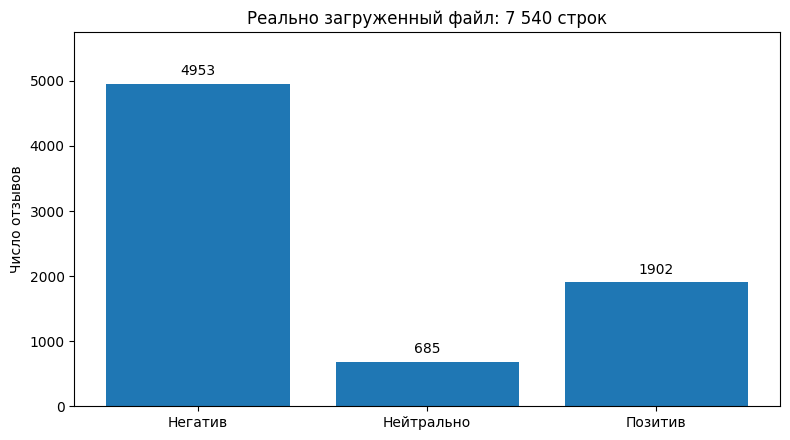

Baseline полного файла: Accuracy=65.69%; Macro-F1=0.2643


In [ ]:
from IPython.display import display, Markdown

all_reviews, data_audit = load_data(CFG)
pilot = choose_pilot(all_reviews, CFG.pilot_size, CFG.seed)
ROOT = Path(CFG.output_dir)
ROOT.mkdir(parents=True, exist_ok=True)
atomic_json(ROOT / "data_audit.json", data_audit)
atomic_csv(ROOT / "pilot_manifest.csv", pilot[["source_row", "text_sha256", "expected"]])

print("Все строки:", len(all_reviews), "| Пилот:", len(pilot))
print("SHA-256:", data_audit["dataset_sha256"])
print("Точных повторов:", data_audit["duplicate_exact_rows"])
print("Групп с конфликтующими метками:", data_audit["groups_with_conflicting_labels"])
display(pd.DataFrame({
    "Полный файл": all_reviews.expected.value_counts().reindex(LABELS),
    "Пилот": pilot.expected.value_counts().reindex(LABELS),
}))

# Небольшой воспроизводимый sample из реального файла, не придуманные отзывы.
pd.set_option("display.max_colwidth", 240)
display(all_reviews.sample(8, random_state=CFG.seed)[["source_row", "rating", "expected", "text"]])
plot_dataset(all_reviews, ROOT / "figures")

baseline = metric_bundle(all_reviews.expected, ["negative"] * len(all_reviews))
print(f"Baseline полного файла: Accuracy={baseline['accuracy']:.2%}; Macro-F1={baseline['macro_f1']:.4f}")


## 8. Основной эксперимент: 1 000 → весь файл, три модели

Это самая важная вычислительная ячейка. Веса загружаются по очереди, а не все одновременно. Отображается ход расчёта. Промежуточные ответы пишутся после каждой группы; повторное выполнение продолжает совместимый кэш.

На CPU это может занять значительное время. Время зависит от устройства, длины текстов, сети и кэша. Здесь не обещается заранее определённая продолжительность или точность.


In [ ]:
russian_outputs, russian_status = run_russian(all_reviews, pilot, CFG, data_audit)
print("Общий статус:", json.dumps(russian_status, ensure_ascii=False, indent=2))

if not russian_status["core_completed"]:
    print("Основной эксперимент НЕ ЗАВЕРШЁН. Ошибки сохранены в run_status.json.")
else:
    print("Основной эксперимент выполнен на всех запрошенных строках.")
print("full_completed =", russian_status["full_completed"])



pilot_1000: RuBERT-tiny balanced; строк: 1000


tokenizer_config.json:   0%|          | 0.00/377 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (28 outputs left out)

Accuracy=0.4870; Macro-F1=0.4470

full: RuBERT-base / RuSentiment; строк: 7540


RuBERT-base / RuSentiment:   0%|          | 0/205 [00:00<?, ?группа/s]

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Accuracy=0.5202; Macro-F1=0.4366
Общий статус: {
  "code": "sentiment-benchmark-5.0",
  "core_completed": true,
  "full_completed": true,
  "source_rows": 7540,
  "scopes": {
    "pilot_1000": {
      "expected_rows": 1000,
      "models": {
        "tiny": {
          "completed": true,
          "rows": 1000,
          "revision": "e0679dd4460e48648f5d4d819ae0f505384f5a9d",
          "device": "cpu",
          "dtype": "float32",
          "new_unique_texts": 1000,
          "reused_unique_texts": 0,
          "load_seconds_this_call": 29.437359907999962,
          "inference_seconds_this_call": 31.71819445899996,
          "elapsed_seconds_this_call": 61.803491441000006,
          "unique_text_inference_seconds_in_cache": 31.71819445899996,
          "note": "Время загрузки/скачивания отдельно; доля batch_seconds_share не является измерением отдельного отзыва."
        },
        "tiny2": {
          "completed": true,
          "rows": 1000,
          "revision": "ad9be38671d444494

## 9. Численные результаты и графики

Пилот и полный файл показываются отдельно. Значения здесь рассчитываются, а не вписываются вручную. `paired_bootstrap.csv` содержит парные различия на одном наборе строк; интервалы не исправляют недостатки исходной звёздной разметки.


### pilot_1000

,key,model,n,accuracy,macro_f1,balanced_accuracy,invalid_count
0,tiny,RuBERT-tiny balanced,1000,0.553,0.4556,0.4935,0
1,tiny2,RuBERT-tiny2,1000,0.485,0.4469,0.5198,0
2,base,RuBERT-base / RuSentiment,1000,0.514,0.4299,0.4881,0
3,always_negative,Всегда негатив — baseline,1000,0.657,0.2643,0.3333,0


,model,class,precision,recall,f1-score,support
0,RuBERT-tiny balanced,negative,0.7796,0.6408,0.7034,657.0
1,RuBERT-tiny balanced,neutral,0.1402,0.4945,0.2184,91.0
2,RuBERT-tiny balanced,positive,0.6259,0.3452,0.4450,252.0
3,RuBERT-tiny2,negative,0.8142,0.5068,0.6248,657.0
4,RuBERT-tiny2,neutral,0.1314,0.7033,0.2215,91.0
5,RuBERT-tiny2,positive,0.8462,0.3492,0.4944,252.0
6,RuBERT-base / RuSentiment,negative,0.8199,0.6027,0.6947,657.0
7,RuBERT-base / RuSentiment,neutral,0.1247,0.6154,0.2074,91.0
8,RuBERT-base / RuSentiment,positive,0.9118,0.2460,0.3875,252.0
9,Всегда негатив — baseline,negative,0.6570,1.0000,0.7930,657.0


,a,b,macro_f1_delta_b_minus_a,ci95_low,ci95_high,bootstrap_repeats,unique_groups
0,pred_tiny,pred_tiny2,-0.0088,-0.0367,0.0207,500,1000
1,pred_tiny,pred_base,-0.0257,-0.0561,0.0049,500,1000
2,pred_tiny2,pred_base,-0.0170,-0.0425,0.0106,500,1000


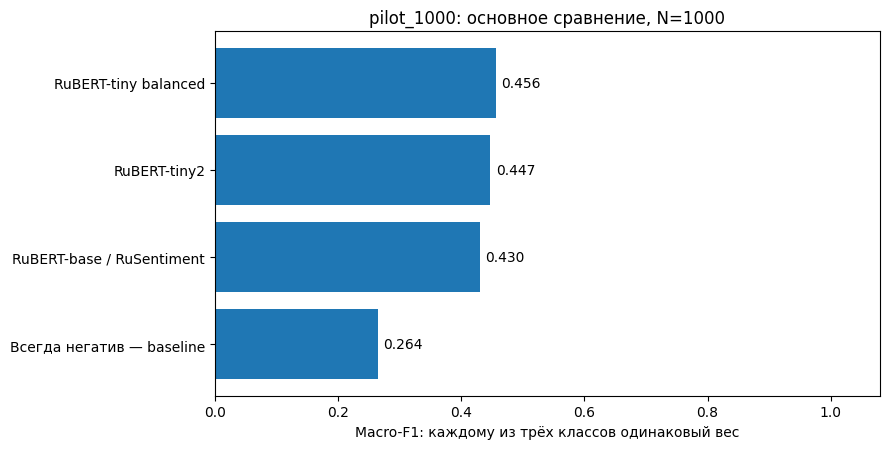

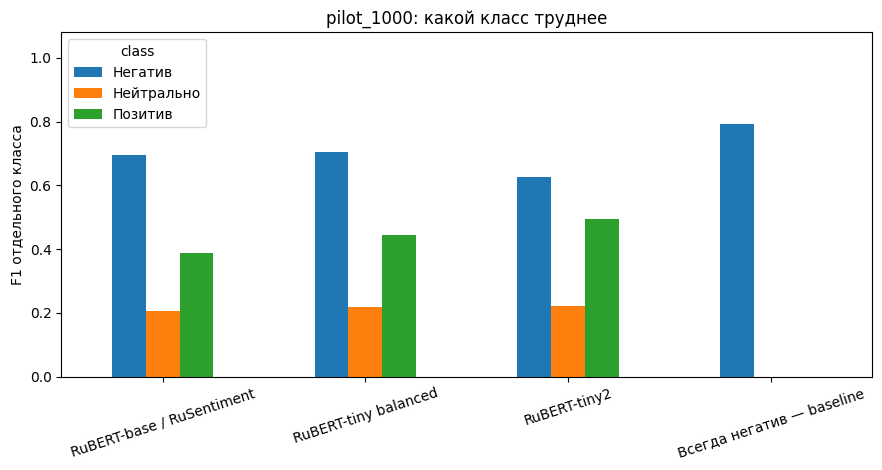

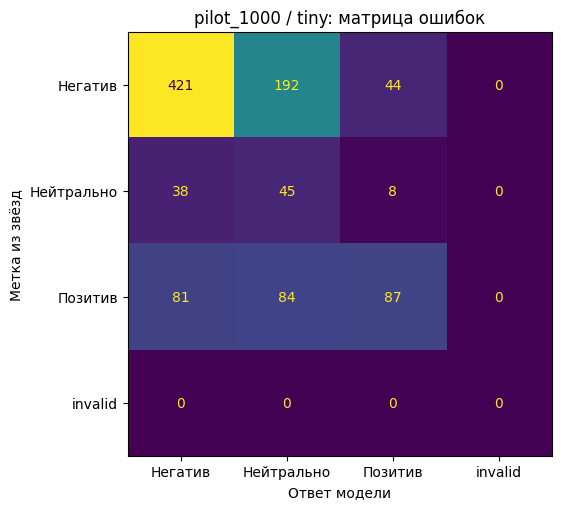

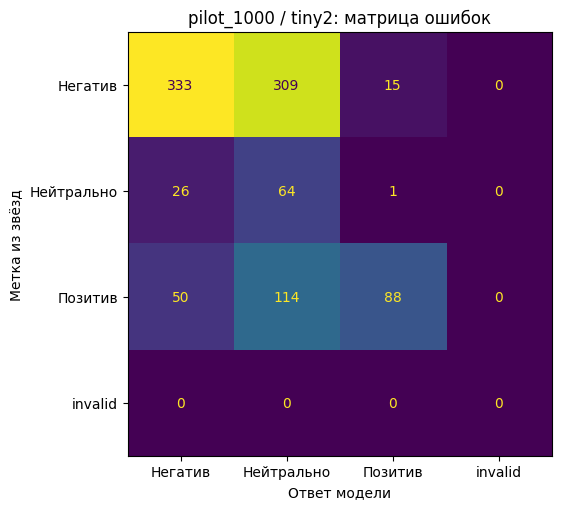

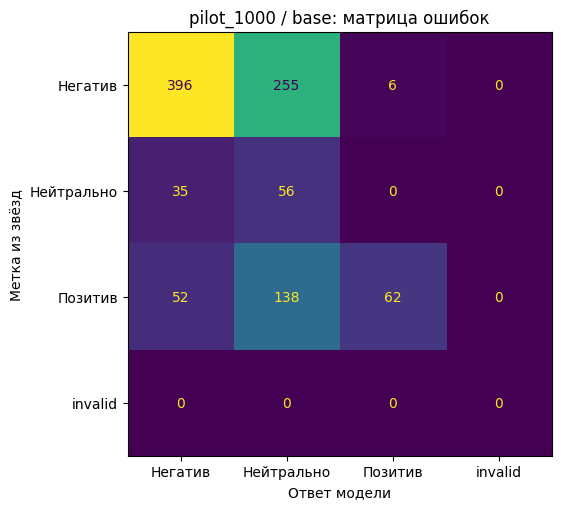

pilot_1000: 1000 строк. По основной метрике Macro-F1 первым оказался RuBERT-tiny balanced: 0.4556; Accuracy=55.30%; balanced accuracy=0.4935.
Разница с правилом 'всегда негатив': +0.1913 Macro-F1 и -10.40 п.п. Accuracy.
Самый слабый класс у этой модели — neutral: F1=0.2184, recall=0.4945, support=91. Распределение ответов: {'negative': 540, 'neutral': 321, 'positive': 139}.
Результат измеряет согласие со звёздами, а не с экспертной разметкой текста. Победа внутри этого сравнения не доказывает пригодность для автоматических решений. Ниже нужно прочитать реальные ошибочные примеры; конкретные причины ошибок нельзя вывести только из метрик.


### full

,key,model,n,accuracy,macro_f1,balanced_accuracy,invalid_count
0,tiny,RuBERT-tiny balanced,7540,0.5531,0.4549,0.4837,0
1,tiny2,RuBERT-tiny2,7540,0.4870,0.4470,0.5196,0
2,base,RuBERT-base / RuSentiment,7540,0.5202,0.4366,0.5009,0
3,always_negative,Всегда негатив — baseline,7540,0.6569,0.2643,0.3333,0


,model,class,precision,recall,f1-score,support
0,RuBERT-tiny balanced,negative,0.7824,0.6426,0.7057,4953.0
1,RuBERT-tiny balanced,neutral,0.1276,0.4526,0.1990,685.0
2,RuBERT-tiny balanced,positive,0.6497,0.3559,0.4599,1902.0
3,RuBERT-tiny2,negative,0.8297,0.5124,0.6335,4953.0
4,RuBERT-tiny2,neutral,0.1299,0.7036,0.2193,685.0
5,RuBERT-tiny2,positive,0.8468,0.3428,0.4880,1902.0
6,RuBERT-base / RuSentiment,negative,0.8276,0.6067,0.7001,4953.0
7,RuBERT-base / RuSentiment,neutral,0.1304,0.6467,0.2171,685.0
8,RuBERT-base / RuSentiment,positive,0.9258,0.2492,0.3927,1902.0
9,Всегда негатив — baseline,negative,0.6569,1.0000,0.7929,4953.0


,a,b,macro_f1_delta_b_minus_a,ci95_low,ci95_high,bootstrap_repeats,unique_groups
0,pred_tiny,pred_tiny2,-0.0079,-0.0169,0.0021,500,7535
1,pred_tiny,pred_base,-0.0182,-0.0287,-0.0055,500,7535
2,pred_tiny2,pred_base,-0.0103,-0.0203,-0.0005,500,7535


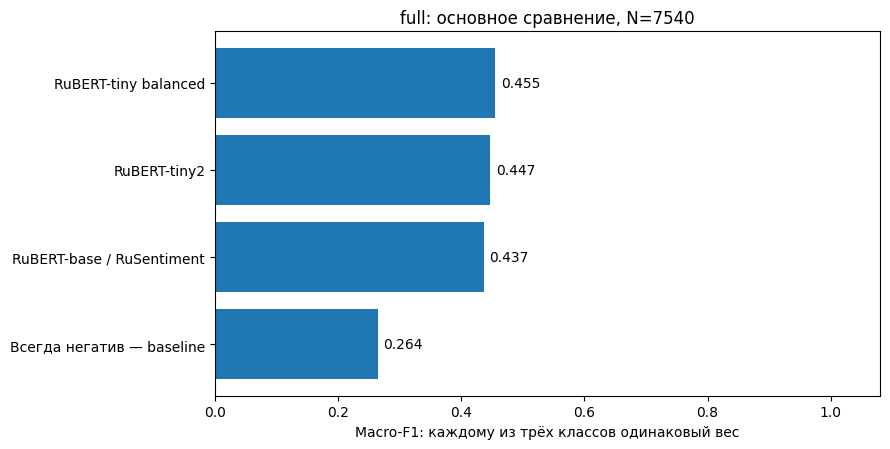

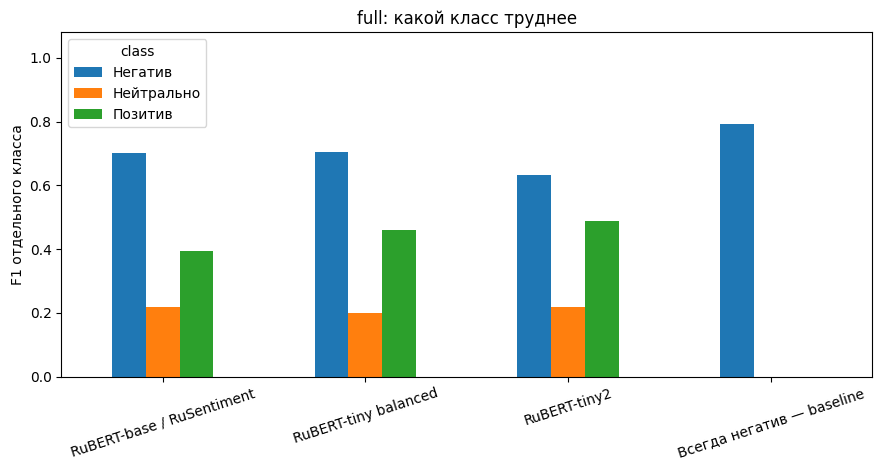

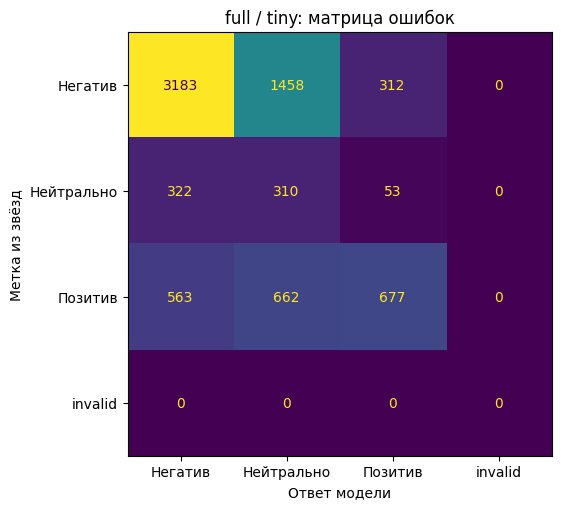

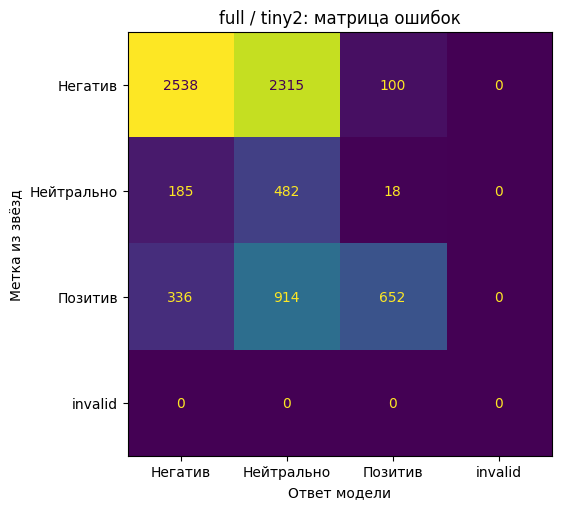

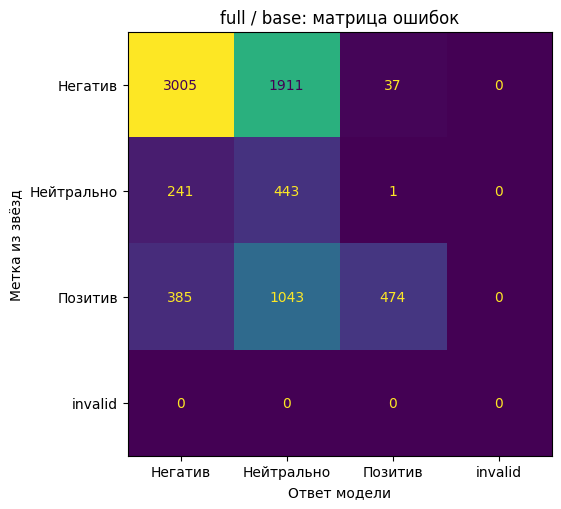

full: 7540 строк. По основной метрике Macro-F1 первым оказался RuBERT-tiny balanced: 0.4549; Accuracy=55.31%; balanced accuracy=0.4837.
Разница с правилом 'всегда негатив': +0.1906 Macro-F1 и -10.38 п.п. Accuracy.
Самый слабый класс у этой модели — neutral: F1=0.1990, recall=0.4526, support=685. Распределение ответов: {'negative': 4068, 'neutral': 2430, 'positive': 1042}.
Результат измеряет согласие со звёздами, а не с экспертной разметкой текста. Победа внутри этого сравнения не доказывает пригодность для автоматических решений. Ниже нужно прочитать реальные ошибочные примеры; конкретные причины ошибок нельзя вывести только из метрик.


In [ ]:
for scope, output in russian_outputs.items():
    display(Markdown(f"### {scope}"))
    display(output["table"].round(4))
    display(output["per_class"].round(4))
    display(output["pairwise"].round(4))
    plot_comparison(output, scope, ROOT / scope / "figures")
    conclusion = summarize_scope(output, scope)
    print(conclusion)
    (ROOT / scope / "numeric_conclusions.txt").write_text(conclusion, encoding="utf-8")

if not russian_outputs:
    print("Таблиц сравнения нет: реальные ответы трёх моделей ещё не получены.")


Эксперимент успешно завершён: все три нейросети обработали 7 540 отзывов. Ошибок выполнения не было, full_completed = True.
1. Сравнение трёх моделей

| Модель |	Accuracy |	Macro-F1 |
| --- | --- | --- |
| RuBERT-tiny balanced |	55,31% |	0,455 |
| RuBERT-tiny2 |	48,70% |	0,447 |
| RuBERT-base / RuSentiment |	52,02% |	0,437 |
| Всегда негатив (baseline) |	65,69% |	0,264 |

Лучшая по основной метрике — RuBERT-tiny balanced.

Она не самая крупная, но лучше остальных сбалансировала распознавание трёх классов.

2. Что показали метрики
- Accuracy — процент совпадений с оценками из звёзд.
- Macro-F1 — качество с одинаковым весом негатива, нейтрального класса и позитива.
- Precision — насколько часто модель права, когда выбирает определённый класс.
- Recall — какую долю отзывов нужного класса она обнаружила.
Почему Macro-F1 важнее Accuracy? В данных 65,7% негативных отзывов. Если всегда отвечать «негатив», Accuracy будет высокой, но остальные классы вообще не распознаются.

3. Что получилось хорошо и плохо

Хорошо:
- Все модели превосходят baseline по Macro-F1.
- Лучше всего распознаётся негатив: у победителя F1 = 0,706.
- Сравнение на 1 000 и 7 540 отзывах дало близкие результаты, что говорит об устойчивости оценок внутри этого набора.

Проблемы:
- Хуже всего распознаётся нейтральный класс: F1 победителя всего 0,199.
- Положительные отзывы тоже определяются неуверенно: F1 = 0,460.
- Модели часто путают нейтральные отзывы с отрицательными и положительными.

4. Главный вывод
Задача технически выполнена, но качество моделей пока недостаточно для полностью автоматической классификации.

Лучшей оказалась RuBERT-tiny balanced с Macro-F1 = 0,455. Однако её преимущество перед RuBERT-tiny2 небольшое: доверительный интервал разницы включает ноль, поэтому нельзя уверенно утверждать, что она лучше на новых данных.


## 10. Разбор настоящих ошибок и ограничений

Ниже — реальные расхождения между текстовым классификатором и рейтингом, а не заранее заданные примеры. Для каждой модели показываются два случайно выбранных случая из каждой наблюдавшейся пары ошибочных классов. Выбор фиксирован `seed` и не подбирается под красивую историю.

При чтении различайте: (а) очевидную ошибку модели; (б) несоответствие звёзд тексту; (в) смешанную оценку нескольких аспектов; (г) иронию/неясный контекст; (д) длинный отзыв, разделённый на части. Категории — вопросы для проверки, **не автоматически доказанные причины**.

Для защиты нужно уметь объяснить несколько показанных случаев своими словами. Одного автоматически сгенерированного абзаца недостаточно, если преподаватель требует содержательного разбора.


In [ ]:
# Предпочитаем полный файл; при незавершённом полном этапе явно используем только пилот.
main_scope = "full" if "full" in russian_outputs else next(iter(russian_outputs), None)
if main_scope is not None:
    errors = russian_outputs[main_scope]["errors"]
    print("Источник разбора:", main_scope)
    for spec in CORE_MODELS:
        subset = errors.loc[errors.model.eq(spec.name)]
        display(Markdown(f"#### {spec.name}"))
        if subset.empty:
            print("На этом наборе нет расхождений с метками рейтинга.")
            continue
        pieces = []
        for _, group in subset.groupby(["expected", "predicted"], sort=True):
            pieces.append(group.sample(min(2, len(group)), random_state=CFG.seed))
        examples = pd.concat(pieces, ignore_index=True)
        display(examples[["source_row", "rating", "expected", "predicted", "n_chunks", "text"]])
        atomic_csv(ROOT / main_scope / f"error_examples_{spec.key}.csv", examples)
else:
    print("Пока нельзя разбирать ошибки новых моделей: нет завершённых предсказаний.")


Источник разбора: full


#### RuBERT-tiny balanced

,source_row,rating,expected,predicted,n_chunks,text
0,6652,1,negative,neutral,1,"Проблема\nНе нажимается кнопка регистрации, помогите"
1,3744,2,negative,neutral,1,"Новое обновление приложения\nВерните приложению старый вид, новое не удобное. Перекидываешь деньги с карты на вклад не показывает остаток на карте. Зато показывает главным окном сколько денег на вкладе. Приходиться считать сколько оста..."
2,4793,1,negative,positive,1,Supersell\nЭто вом за стоь сорак мигаящикав
3,129,2,negative,positive,1,"Одно из самых неудобных банковских приложений\n1. СБП запрятано в самом низу. Очень неочевидное место. Я, конечно, понимаю, что Сберу очень выгодно брать комиссии за переводы, но все-таки:)\n2. Возможность переводить тебе через СПБ надо..."
4,4625,3,neutral,negative,1,Сбербанк онлайн\nПерестал работать
5,3644,3,neutral,negative,1,"«Все для клиента»\nДобавьте уже частичное досрочное погашение с уменьшением срока. Что за бред таскаться в отделение каждый раз! Настолько хочется каждую копейку забрать у клиентов, надеясь, что им лень будет пойти из-за пары тысяч?"
6,3515,3,neutral,positive,1,"Поддержка iOS 9\nПоддержку старых iOS заделайте! Отрубили всем поддержку старых устройств, которые ещё работают."
7,6203,3,neutral,positive,1,Обновление не очень\nСтарый интерфейс нравился больше
8,3606,5,positive,negative,1,Куда ВСЁ исчезло?!\nКак из просмотра одной Карты перейти к просмотру другой? \nА никак!!! Криворукие
9,6760,5,positive,negative,1,Отзыв\nСбербанк 10 из 10 иметься карта тинькоф абсалют ! Все это только карты и приложение у них не ахти ! Сбер на другом уровне по приложение и сервису


#### RuBERT-tiny2

,source_row,rating,expected,predicted,n_chunks,text
0,1969,2,negative,neutral,1,Интерфейс\nНе устраивает расположение голосового помощника на главном экране. Я им не пользуюсь и он мне мешает. Как можно его убрать?
1,2651,1,negative,neutral,1,"Не открывается приложение\nСегодня никак не могу зайти, связь нормальная и памяти в телефоне хватает"
2,5751,1,negative,positive,1,за бравл\nтребуем компенсацию за 140 мегаящиков
3,3909,1,negative,positive,1,"«Отличная» консультация в чате\nОтличный сервис... «Любители писать, а не звонить обязательно оценят эту возможность». \nНаписала по поводу смены номера телефона для мобильного банка, на что получила ответ: \n«Для уточнения возможности ..."
4,1136,3,neutral,negative,1,"Верните прошлуюВерсию\nПочему то исчезли «свои» папки куда ты сам распределял финансы, очень неудобно, верните предыдущую версию"
5,2263,3,neutral,negative,1,"Испортили логотип и есть минусы в приложении\nРаньше логотип был узнаваемым, сейчас совершенно сливается со всем остальным. Приложение наводнили информационным мусором, что замедляет работу и усложняет функционал. Сделайте возможность с..."
6,602,3,neutral,positive,1,"Версия для iPad\nУважаемые разработчики, стоит ли ждать наконец-то полноценную версию для iPad или уже стоит от Вас уходить в ВТБ ?"
7,1070,3,neutral,positive,1,Захламили\nСлабо адаптировано для незрячих. Скучаю по старому сберу без кучи лишних клавиш и предложений.
8,2106,4,positive,negative,1,Отзыв\nОоочень раздражают диалоги которые постоянно высвечиваются значком на приложении и их постоянно приходится прочитывать чтобы они исчезли
9,2874,5,positive,negative,1,Отст\nСбербанк тестировался новую версию приложение и предложил помочь в совершенствовании и тестировании. В итоге срок тестирования истёк и приложение на телефоне рухнуло! Единственное что мне могли предложить это заново загрузить прил...


#### RuBERT-base / RuSentiment

,source_row,rating,expected,predicted,n_chunks,text
0,4645,1,negative,neutral,1,"Проблема активации карт и оформление электронных карт.\nНажимаю на кнопку активировать, для активации карты где горит зелёная галочка, уже какой день пишет активация карты не возможна, попробуйте через 5 мин. Решите эту проблему, что за..."
1,443,1,negative,neutral,1,"Хватит навязывать!\nС чего ради вы решили, что две карты на экране удобней чем три? Да еще и преподносите это так, что вам лучше знать, что для меня удобней."
2,2936,1,negative,positive,1,Классное приложение!\nПочему баланс карты можно смотреть бесплатно?! Добавьте подписку!! А так молодцы! 😊
3,2712,1,negative,positive,1,Эргономика\nСтарый интерфейс был удобней.
4,971,3,neutral,negative,1,"СПб\nЧтобы сделать перевод через сбп, нужно быть сотрудником банка! Самостоятельно клиенты разобраться не смогут, неудобно и наверчено много всего"
5,260,3,neutral,negative,1,Перемудрили\nИз приложения сделали помойку. Глаз не цепляется вообще ни за что. Сервис сервисом погоняет. Последовательности и структуры нет совсем! Несколько каруселей на основном экране не кажется Вам перебором?
6,2804,3,neutral,positive,1,"версия для iPad\nЗдравствуйте, хочу поблагодарить за отличное приложение, которое продолжает становиться все лучше. Присоединяюсь к многочисленным просьбам обновить наконец версию для iPad!"
7,4543,5,positive,negative,1,Придумайте обход установки на Эппл\nКак то надо яблоко интегрировать в обход их системы а то бесполезный деревяшки а не телефоны
8,4151,5,positive,negative,1,Долбоебизм\nЯ заебалась с вашими картами!!!
9,7501,5,positive,neutral,1,Виджет\nДобавьте уже новый виджет по остаткам средств для iOS 15


## 11. Дополнительный эксперимент: RU против одного сохранённого перевода EN

Здесь используется **одна и та же XLM-R**, одинаковые веса и правило выбора класса. Сначала переводим тексты Marian, затем анализируем оригинал и перевод. Это не обещание, что перевод улучшит качество: перевод способен изменить отрицание, тон и детали.

По умолчанию ветка рассчитана на те же 1 000 строк. Модели основной таблицы — русскоязычные: подавать им английский и объявлять это корректным тестом нельзя. Готовый `translations.csv` можно повторно использовать с другими подходящими английскими/многоязычными моделями без нового перевода.


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

source.spm:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/803k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/307M [00:00<?, ?B/s]

... (12 outputs left out)

{
  "enabled": true,
  "completed": true,
  "expected_rows": 1000,
  "translation": {
    "revision": "fbd6dc73284f95536648512cc21d57f19191961a",
    "new_unique_texts": 1000,
    "elapsed_seconds_this_call": 2861.820499803,
    "empty_count": 0,
    "limit_reached_count": 1,
    "contains_cyrillic_count": 0,
    "note": "Флаги — повод для ручной проверки, НЕ измеренная точность перевода. Эталонных переводов нет."
  },
  "rows": 1000,
  "corrected": 72,
  "worsened": 90,
  "ru_timing": {
    "revision": "f2f1202b1bdeb07342385c3f807f9c07cd8f5cf8",
    "device": "cpu",
    "dtype": "float32",
    "new_unique_texts": 1000,
    "reused_unique_texts": 0,
    "load_seconds_this_call": 29.705437446999895,
    "inference_seconds_this_call": 266.1159676469988,
    "elapsed_seconds_this_call": 296.47878266600037,
    "unique_text_inference_seconds_in_cache": 266.1159676469988,
    "note": "Время загрузки/скачивания отдельно; доля batch_seconds_share не является измерением отдельного отзыва."
  }

,key,model,n,accuracy,macro_f1,balanced_accuracy,invalid_count
0,xlmr_ru,XLM-R: русский,1000,0.632,0.4866,0.4818,0
1,xlmr_en,XLM-R: перевод на английский,1000,0.614,0.4564,0.4470,0
2,always_negative,Всегда негатив — baseline,1000,0.657,0.2643,0.3333,0


,model,class,precision,recall,f1-score,support
0,XLM-R: русский,negative,0.7666,0.7747,0.7706,657.0
1,XLM-R: русский,neutral,0.1215,0.2857,0.1705,91.0
2,XLM-R: русский,positive,0.7951,0.3849,0.5187,252.0
3,XLM-R: перевод на английский,negative,0.7559,0.7778,0.7667,657.0
4,XLM-R: перевод на английский,neutral,0.0969,0.2418,0.1384,91.0
5,XLM-R: перевод на английский,positive,0.8351,0.3214,0.4642,252.0
6,Всегда негатив — baseline,negative,0.6570,1.0000,0.7930,657.0
7,Всегда негатив — baseline,neutral,0.0000,0.0000,0.0000,91.0
8,Всегда негатив — baseline,positive,0.0000,0.0000,0.0000,252.0


,a,b,macro_f1_delta_b_minus_a,ci95_low,ci95_high,bootstrap_repeats,unique_groups
0,pred_xlmr_ru,pred_xlmr_en,-0.0302,-0.0572,-0.0034,500,1000


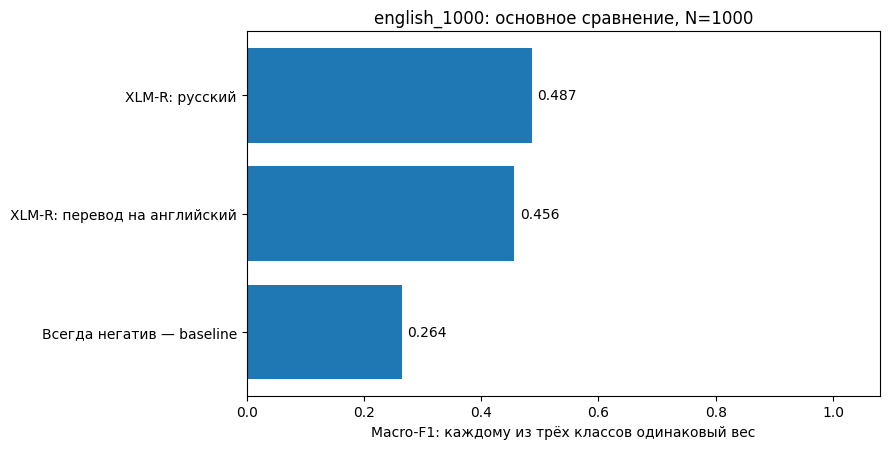

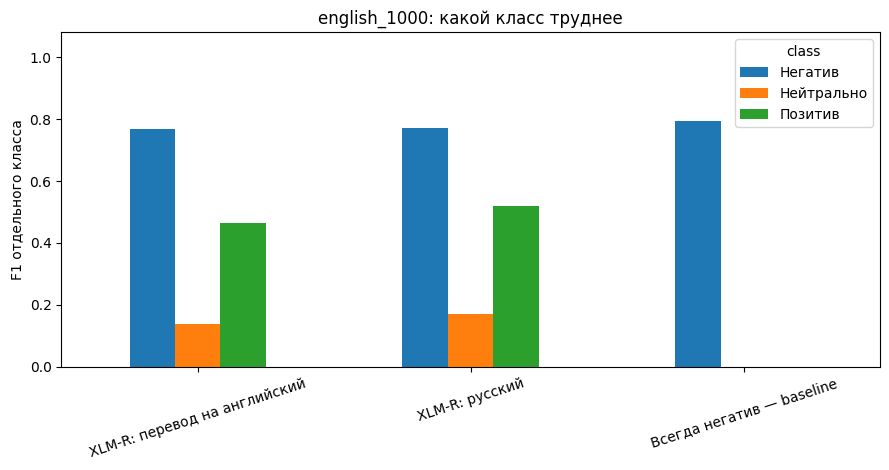

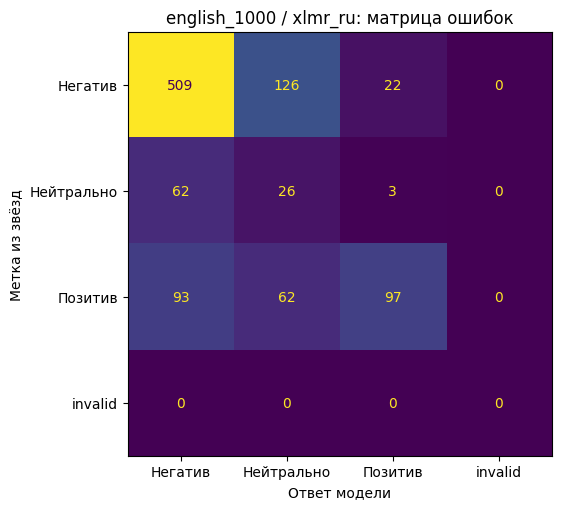

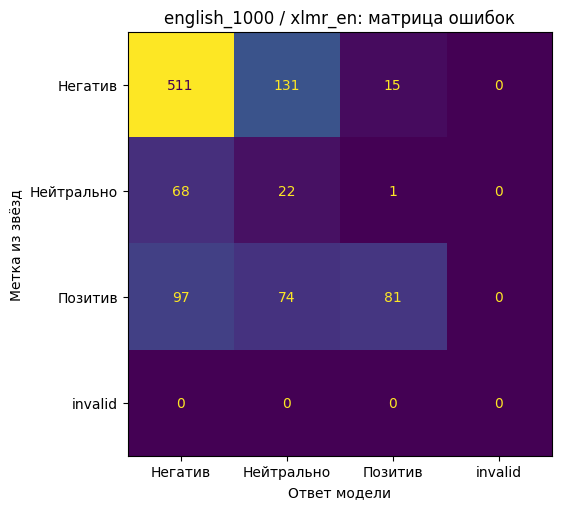

Перевод исправил ответов: 72
Перевод ухудшил ответов: 90


,source_row,text,text_en,expected,pred_xlmr_ru,pred_xlmr_en,translation_limit_reached,translation_contains_cyrillic
521,3944,"Останавливается музыка\n1. Включаем музыку\n2. Совершаем перевод \n\nОР: Музыка продолжил играть в фоне, как это было всегда \nФР: Музыка останавливается , приходится включать вручную. Остановка происходит не только по время перевода , ...","1. Turn on music 2. We're going to translate OR: Music continued to play in the background, as was always the FF: Music stops, has to turn on by hand. Stop not only when translation takes place, there are more briefcases, but I don't re...",positive,neutral,neutral,False,False
737,5622,"Сегодня\nЗамечательная девушка проконсультировала все объяснила, очень хороший сотрудник спасибо)))","A wonderful girl gave her advice today, a very good employee, thank you.))",positive,positive,positive,False,False
740,5634,"Уведомления по операциям с дебетовой и кредитной картами, проблемы с получением уведомлений\nПроблемы с получением уведомлений по операциям с картами","Notifications on debit and credit card transactions, problems in receiving notifications Problems in receiving notification on card transactions",positive,neutral,negative,False,False
660,4904,)\nНе советую этот банк \nсамый ужасный банк который я когда либо встречал !,) I don't recommend this bank the worst bank I've ever met!,negative,negative,negative,False,False
411,3206,"Почти 300 мег. Вы серьёзно?!\nТам что, бегемот?! Ах да, мессенджер, магаз, и что у вас там ещё?\nА можно простое приложение по делу, а доп - сервисы отдельно? Ведь мало кто будет использовать приложение для посторонних целей хотя бы из ...","You're serious? There aren't many people who would use the app for any other purpose, even for security reasons! Why are people with old iOs hurt? The cost of space? People in crisis should update the gadgets? How did you not care about...",neutral,negative,negative,False,False
678,5116,Спасибо Сбербанк\nУдобное приложение Сбербанка. Спасибо операторам за оперативность и компетентность! Быстро решили мой вопрос),"Thank you, Sberbank. It's a convenient Sberbank app. Thank you to the operators for your speed and competence.",positive,positive,positive,False,False
626,4649,Ирина\nСпасибо за бесперебойную работу.,"Irina, thank you for your smooth work.",positive,positive,positive,False,False
513,3895,"Сбербанк - это ужас\nСбербанк - один большой минус. Переводы в другой регион - комиссия. Снятие со своей карты в другом регионе - комиссия. Страшно представить, куда идут эти деньги. У других банков такого ужаса не встречал. Очень жаль,...","Sberbank is the horror of Sberbank, one big minus. Transfers to another region are the commission. Take off your map in another region is the commission. It's scary to see where that money goes. Other banks don't have that horror. It's ...",negative,negative,negative,False,False


english_1000: 1000 строк. По основной метрике Macro-F1 первым оказался XLM-R: русский: 0.4866; Accuracy=63.20%; balanced accuracy=0.4818.
Разница с правилом 'всегда негатив': +0.2223 Macro-F1 и -2.50 п.п. Accuracy.
Самый слабый класс у этой модели — neutral: F1=0.1705, recall=0.2857, support=91. Распределение ответов: {'negative': 664, 'neutral': 214, 'positive': 122}.
Результат измеряет согласие со звёздами, а не с экспертной разметкой текста. Победа внутри этого сравнения не доказывает пригодность для автоматических решений. Ниже нужно прочитать реальные ошибочные примеры; конкретные причины ошибок нельзя вывести только из метрик.


In [ ]:
english_output, english_status = run_english(all_reviews, pilot, CFG, data_audit)
print(json.dumps(english_status, ensure_ascii=False, indent=2))
if english_output is not None:
    display(english_output["table"].round(4))
    display(english_output["per_class"].round(4))
    display(english_output["pairwise"].round(4))
    english_scope_name = f"english_{english_status['rows']}"
    plot_comparison(english_output, english_scope_name, ROOT / english_scope_name / "figures")
    print("Перевод исправил ответов:", english_status["corrected"])
    print("Перевод ухудшил ответов:", english_status["worsened"])
    wide = english_output["wide"]
    display(wide.sample(min(8,len(wide)), random_state=CFG.seed)[[
        "source_row", "text", "text_en", "expected", "pred_xlmr_ru", "pred_xlmr_en",
        "translation_limit_reached", "translation_contains_cyrillic",
    ]])
    conclusion_en = summarize_scope(english_output, english_scope_name)
    print(conclusion_en)
    (ROOT / english_scope_name / "numeric_conclusions.txt").write_text(conclusion_en, encoding="utf-8")
else:
    print("Английские метрики не подставлены: этап выключен или не завершён.")


## 12. Итоговые файлы и проверка завершения

Результаты сохраняются отдельными CSV и JSON в папку `sentiment_results`. Распаковка архива не требуется. Полный основной этап закончен только при `full_completed=True`; это подтверждается проверкой всех строк и трёх столбцов предсказаний. Английский этап имеет отдельный статус.

В коде отсутствует платный сервис вычисления предсказаний. Бесплатность выбранной вычислительной среды определяется режимом вашего Colab. Ноутбук не оформляет подписки и не запрашивает платёжные данные.


In [ ]:
final_status = {
    "source_rows": len(all_reviews),
    "pilot_rows": len(pilot),
    "core_models": [model.repo for model in CORE_MODELS],
    "full_completed": russian_status["full_completed"],
    "english_completed": english_status.get("completed", False),
    "english_rows": english_status.get("rows", 0),
    "paid_inference_api_used_by_this_code": False,
}
if final_status["full_completed"]:
    full_saved = pd.read_csv(ROOT / "full" / "predictions.csv")
    assert len(full_saved) == len(all_reviews) == CFG.expected_rows
    assert full_saved.source_row.is_unique
    assert set(full_saved.source_row) == set(all_reviews.source_row)
    assert all(f"pred_{model.key}" in full_saved for model in CORE_MODELS)
    print("Проверка полного CSV: все исходные строки и все три модели присутствуют.")
else:
    print("Нельзя объявлять работу полностью выполненной: основной полный этап не завершён.")

atomic_json(ROOT / "FINAL_STATUS.json", final_status)
print(json.dumps(final_status, ensure_ascii=False, indent=2))

# Выводим отдельные файлы результатов: архив открывать не понадобится.
from IPython.display import FileLink, display
print("Результаты находятся в папке:", ROOT.resolve())
for relative in ["FINAL_STATUS.json", "pilot_1000/metrics.csv", "full/metrics.csv", "full/predictions.csv"]:
    path = ROOT / relative
    if path.is_file():
        display(FileLink(str(path)))
print("В Colab эти же файлы можно скачать через боковую панель «Файлы».")


Проверка полного CSV: все исходные строки и все три модели присутствуют.
{
  "source_rows": 7540,
  "pilot_rows": 1000,
  "core_models": [
    "cointegrated/rubert-tiny-sentiment-balanced",
    "seara/rubert-tiny2-russian-sentiment",
    "blanchefort/rubert-base-cased-sentiment-rusentiment"
  ],
  "full_completed": true,
  "english_completed": true,
  "english_rows": 1000,
  "paid_inference_api_used_by_this_code": false
}
Результаты находятся в папке: /content/sentiment_results


/content/sentiment_results/FINAL_STATUS.json

/content/sentiment_results/pilot_1000/metrics.csv

/content/sentiment_results/full/metrics.csv

/content/sentiment_results/full/predictions.csv

В Colab эти же файлы можно скачать через боковую панель «Файлы».


### Результаты дополнительного эксперимента: русский vs английский

Мы проверили 1 000 отзывов с помощью XLM-RoBERTa двумя способами: анализ исходного русского текста и анализ после перевода на английский моделью Helsinki-NLP

| Метрика           | Русский текст | Перевод на английский |
| ----------------- | ------------- | --------------------- |
| Accuracy          | 63,2%         | 61,4%                 |
| Macro-F1          | 0,487         | 0,456                 |
| Balanced Accuracy | 48,2%         | 44,7%                 |

Основные выводы:

- Русский текст показал лучший результат. Перевод снизил Macro-F1 на 0,030.
- Перевод исправил 72 ошибки классификации, но одновременно создал 90 новых.
- Лучше всего распознаётся негатив: F1 = 0,771 на русском.
- Хуже всего — нейтральные отзывы: F1 = 0,171.
- Обе версии превосходят простое правило «всегда негатив» по Macro-F1 (0,264).

Важный момент: перевод 1 000 отзывов занял около 47,5 минуты на CPU, то есть потребовал дополнительных вычислений, но качество ухудшилось

### Итог

Переводить отзывы на английский для этой задачи нецелесообразно. XLM-RoBERTa лучше справилась непосредственно с русским текстом.

При этом XLM-R на русском получила Macro-F1 = 0,487, что выше результата RuBERT-tiny balanced (0,456) на пилотной выборке из 1 000 отзывов.

Таким образом, дополнительный эксперимент позволил найти более перспективную модель, но её качество на всех 7 540 отзывах ещё нужно проверить.

## Итог

Лучшая пока — XLM-RoBERTa (XLM-R) на русском языке.

Почему:
- Macro-F1 = 0,487 — самый высокий результат среди протестированных моделей.
- Accuracy = 63,2%.
- Перевод на английский не нужен — он ухудшил качество.
Нюанс: XLM-R проверена на 1 000 отзывах, а RuBERT — на всех 7 540.

Поэтому XLM-R — лидер предварительного сравнения

In [ ]:

import pandas as pd
from pathlib import Path

path = Path("sentiment_results/full/predictions.csv")
df = pd.read_csv(path)

errors = df[df["expected"] != df["pred_tiny"]]
samples = pd.concat([
    errors[errors["expected"] == label].sample(
        n=min(3, (errors["expected"] == label).sum()),
        random_state=42
    )
    for label in ["negative", "neutral", "positive"]
])

for _, row in samples.iterrows():
    print("=" * 65)
    print(f"ОТЗЫВ №{row['source_row']}")
    print(f"Оценка пользователя: {row['rating']} звёзд")
    print(f"Эталонный класс: {row['expected']}")
    print()
    print("ТЕКСТ ОТЗЫВА:")
    print(row["text"])
    print()
    print("ПРЕДСКАЗАНИЯ:")
    print(f"RuBERT-tiny balanced: {row['pred_tiny']}")
    print(f"RuBERT-tiny2:        {row['pred_tiny2']}")
    print(f"RuBERT-base:         {row['pred_base']}")
    print()

ОТЗЫВ №3488
Оценка пользователя: 2 звёзд
Эталонный класс: negative

ТЕКСТ ОТЗЫВА:
Не могу обновить приложение, место на телефоне есть
Не могу обновить приложение, хотя место на телефоне достаточно

ПРЕДСКАЗАНИЯ:
RuBERT-tiny balanced: neutral
RuBERT-tiny2:        neutral
RuBERT-base:         neutral

ОТЗЫВ №965
Оценка пользователя: 1 звёзд
Эталонный класс: negative

ТЕКСТ ОТЗЫВА:
Бравл
Дайте компенсацию за 140 мегаящиков !

ПРЕДСКАЗАНИЯ:
RuBERT-tiny balanced: neutral
RuBERT-tiny2:        positive
RuBERT-base:         neutral

ОТЗЫВ №1458
Оценка пользователя: 1 звёзд
Эталонный класс: negative

ТЕКСТ ОТЗЫВА:
Никакой обратной связи
Как только ситуация выходит за рамки той, которую отшлифовали в приложении разработчики, готовьтесь страдать.
Штат операторов недостаточен, ждать ответа в чате или по телефону можно очень долго. Бот ничего не понимает, но все время вклинивается. 
Если вам повезёт связаться с оператором, пишите очень быстро, у них инструкция прекращать общение, если пару минут не

Ручной анализ четырёх отзывов выявил существенное ограничение используемого датасета: оценки пользователей в звёздах не всегда отражают эмоциональную окраску текста.

В трёх из четырёх рассмотренных случаев предсказания одной или нескольких моделей оказались содержательно обоснованными, хотя и не совпали с контрольными метками. В частности, модели правильно определяли негативную тональность жалоб, которым пользователи присвоили пять звёзд.

Следовательно, рассчитанные Accuracy и Macro-F1 отражают прежде всего соответствие предсказаний пользовательским рейтингам, а не абсолютную точность определения тональности.



# MVP - Part

In [2]:
import sys
import subprocess
import importlib.util
from importlib.metadata import version, PackageNotFoundError

if sys.version_info < (3, 10):
    raise RuntimeError("Необходим Python 3.10 или новее")

if importlib.util.find_spec("packaging") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "packaging"
    ])

from packaging.requirements import Requirement

requirements = [
    "transformers==4.57.6",
    "huggingface-hub>=0.34,<1",
    "numpy>=1.26,<3",
    "pandas>=2.1,<3",
    "scikit-learn>=1.5,<2",
    "matplotlib>=3.8,<4",
    "tqdm>=4.66,<5"
]

needed = []

for requirement in requirements:
    req = Requirement(requirement)

    try:
        installed = version(req.name)
    except PackageNotFoundError:
        installed = None

    if installed is None or not req.specifier.contains(installed):
        needed.append(requirement)

if needed:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", *needed
    ])

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "torch>=2.6,<3"
    ])


In [4]:
import os
import re
import gc
import json
import time
import hashlib

from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from huggingface_hub import hf_hub_download

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display

os.environ["HF_HUB_DISABLE_IMPLICIT_TOKEN"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Новый источник данных
DATASET = "Romjiik/Russian_bank_reviews"
FILENAME = "final_review_dataset_extended.csv"

# Можно подставить собственный CSV
LOCAL_CSV = None

# Лучшая модель из нашего предыдущего сравнения
MODEL_ID = "cardiffnlp/twitter-xlm-roberta-base-sentiment"

# Фиксируем версию модели для воспроизводимости
MODEL_REV = "f2f1202b1bdeb07342385c3f807f9c07cd8f5cf8"

LABELS = ["negative", "neutral", "positive"]

LABEL_RU = [
    "Негатив",
    "Нейтрально",
    "Позитив"
]

OUTPUT = Path("mvp_results")
OUTPUT.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

DOC_BATCH = 12 if DEVICE == "cuda" else 6
TOKEN_BATCH = 12 if DEVICE == "cuda" else 4

MAX_TOKENS = 512

# Порог неопределённости — предварительная настройка MVP.
# Это НЕ калиброванная вероятность ошибки.
UNCERTAIN_MARGIN = 0.15

print("Устройство:", DEVICE)
print("Модель:", MODEL_ID)

Устройство: cpu
Модель: cardiffnlp/twitter-xlm-roberta-base-sentiment


ЗАГРУЗКА НОВОГО ДАТАСЕТА

In [5]:

if LOCAL_CSV:
    csv_path = Path(LOCAL_CSV).expanduser()

elif Path(FILENAME).exists():
    csv_path = Path(FILENAME)

else:
    try:
        csv_path = Path(
            hf_hub_download(
                repo_id=DATASET,
                repo_type="dataset",
                filename=FILENAME,
                token=False
            )
        )
    except Exception as exc:
        raise RuntimeError(
            "Не удалось автоматически скачать датасет. "
            "Загрузите final_review_dataset_extended.csv "
            "со страницы Romjiik/Russian_bank_reviews "
            "на Hugging Face и поместите рядом с ноутбуком. "
            f"Подробности: {str(exc)[:200]}"
        ) from exc

if not csv_path.exists():
    raise FileNotFoundError(csv_path)

# Контрольная сумма исходного файла
file_sha = hashlib.sha256(csv_path.read_bytes()).hexdigest()

raw = pd.read_csv(
    csv_path,
    encoding="utf-8-sig",
    low_memory=False
)

if raw.empty:
    raise ValueError("CSV не содержит отзывов")

# Определяем названия столбцов
text_col = (
    "review" if "review" in raw else
    "text" if "text" in raw else None
)

rating_col = (
    "rating_value" if "rating_value" in raw else
    "rating" if "rating" in raw else None
)

title_col = (
    "review_title" if "review_title" in raw else
    "title" if "title" in raw else None
)

if text_col is None:
    raise ValueError("Нужен столбец review или text")

reviews = pd.DataFrame({
    "source_row": np.arange(len(raw))
})

reviews["bank"] = (
    raw["bank"].fillna("Не указан").astype(str).to_numpy()
    if "bank" in raw else "Не указан"
)

reviews["review"] = (
    raw[text_col].fillna("").astype(str).to_numpy()
)

reviews["title"] = (
    raw[title_col].fillna("").astype(str).to_numpy()
    if title_col else ""
)

# Объединяем название и основной текст
reviews["text"] = (
    reviews["title"] + "\n" + reviews["review"]
).str.strip()

reviews["rating"] = (
    pd.to_numeric(raw[rating_col], errors="coerce").to_numpy()
    if rating_col else np.nan
)

# Контрольные метки из пользовательских звёзд.
# Они не передаются нейросети.
reviews["expected"] = reviews["rating"].map({
    1: "negative",
    2: "negative",
    3: "neutral",
    4: "positive",
    5: "positive"
})

reviews["text_sha256"] = reviews["text"].map(
    lambda s: hashlib.sha256(
        s.encode("utf-8")
    ).hexdigest()
)

print("\nИнформация о новом наборе данных")
print("Всего отзывов:", len(reviews))
print("Количество банков:", reviews.bank.nunique())
print("С контрольными метками:", reviews.expected.notna().sum())
print("Повторяющихся текстов:", reviews.text_sha256.duplicated().sum())

display(
    reviews.sample(
        min(5, len(reviews)),
        random_state=42
    )[["bank", "rating", "text"]]
)

final_review_dataset_extended.csv:   0%|          | 0.00/23.5M [00:00<?, ?B/s]


Информация о новом наборе данных
Всего отзывов: 12392
Количество банков: 86
С контрольными метками: 12392
Повторяющихся текстов: 0


,bank,rating,text
624,Почта Банк,5,Постоянные необоснованные звонки\nПросто отвра...
2271,ВТБ,2,Я помогу вам найти лучший банк. Спойлер-не ВТБ...
7762,Россельхозбанк,5,Отличный банк и хорошее обслуживание\nОбращала...
6829,Сбербанк,1,Обман банка\nТак же самая ситуация. В кредитно...
9871,ЮниКредит Банк,1,Не закрывают счета по давно погашенной ипотеке...


# ЗАГРУЗКА XLM-R И ПРЕДСКАЗАНИЯ

In [6]:

class SentimentModel:
    """
    Готовая нейросеть для классификации отзывов.
    Дообучение на новом наборе не выполняется.
    """

    def __init__(self):

        # Загружаем токенизатор заново
        self.tokenizer = AutoTokenizer.from_pretrained(
            MODEL_ID,
            revision=MODEL_REV,
            token=False
        )

        # Загружаем веса нейросети заново
        self.model = (
            AutoModelForSequenceClassification.from_pretrained(
                MODEL_ID,
                revision=MODEL_REV,
                token=False,
                dtype=torch.float32
            )
            .to(DEVICE)
            .eval()
        )

        # Проверяем соответствие индексов классов
        id2label = {
            str(v).lower().strip(): int(k)
            for k, v in self.model.config.id2label.items()
        }

        if not set(LABELS).issubset(id2label):
            raise ValueError(
                f"Неизвестные метки модели: {self.model.config.id2label}"
            )

        self.order = [id2label[x] for x in LABELS]

        self.limit = (
            min(MAX_TOKENS, int(self.model.config.max_position_embeddings))
            - self.tokenizer.num_special_tokens_to_add(pair=False)
        )

        if self.limit < 32:
            raise ValueError("Слишком маленький контекст модели")

        if DEVICE == "cpu":
            torch.set_num_threads(
                min(4, os.cpu_count() or 1)
            )

        print("\nXLM-R успешно загружена на", DEVICE)

    def _forward(self, features):
        """Непосредственный запуск нейросети."""

        tensors = self.tokenizer.pad(
            features,
            padding=True,
            return_tensors="pt"
        ).to(DEVICE)

        try:
            with torch.inference_mode():
                logits = self.model(**tensors).logits.float()

                return (
                    logits.softmax(-1)[:, self.order]
                    .cpu()
                    .numpy()
                )

        except torch.cuda.OutOfMemoryError:
            del tensors

            if DEVICE == "cuda":
                torch.cuda.empty_cache()

            if len(features) == 1:
                raise

            middle = len(features) // 2

            return np.vstack([
                self._forward(features[:middle]),
                self._forward(features[middle:])
            ])

    def predict(self, texts):
        """
        Возвращает тональность каждого отзыва.
        Длинные отзывы обрабатываются частями.
        """

        features = []
        owners = []
        weights = []
        lengths = []

        for i, text in enumerate(texts):

            # Предобработка URL и упоминаний
            normalized = re.sub(
                r"https?://\S+",
                "http",
                text
            )

            normalized = re.sub(
                r"(?<!\w)@\w+",
                "@user",
                normalized
            )

            ids = self.tokenizer.encode(
                normalized,
                add_special_tokens=False,
                truncation=False
            )

            # Делим длинные отзывы на фрагменты
            parts = [
                ids[j:j + self.limit]
                for j in range(0, len(ids), self.limit)
            ]

            lengths.append((len(ids), len(parts)))

            for part in parts:

                features.append(
                    self.tokenizer.prepare_for_model(
                        part,
                        add_special_tokens=True,
                        return_attention_mask=True,
                        return_token_type_ids=(
                            "token_type_ids"
                            in self.tokenizer.model_input_names
                        )
                    )
                )

                owners.append(i)
                weights.append(len(part))

        weighted = np.zeros((len(texts), 3), dtype=float)
        denominators = np.zeros(len(texts), dtype=float)

        order = sorted(
            range(len(features)),
            key=lambda j: len(features[j]["input_ids"])
        )

        for j in range(0, len(order), TOKEN_BATCH):

            indices = order[j:j + TOKEN_BATCH]

            scores = self._forward([
                features[k] for k in indices
            ])

            for k, score in zip(indices, scores):

                weighted[owners[k]] += score * weights[k]
                denominators[owners[k]] += weights[k]

        answers = []

        for i, (n_tokens, n_chunks) in enumerate(lengths):

            if denominators[i] == 0:

                answers.append({
                    "predicted": "invalid",
                    "n_tokens": 0,
                    "n_chunks": 0,
                    **{
                        f"score_{label}": None
                        for label in LABELS
                    }
                })

            else:
                score = weighted[i] / denominators[i]

                answers.append({
                    "predicted": LABELS[int(score.argmax())],
                    "n_tokens": n_tokens,
                    "n_chunks": n_chunks,
                    **{
                        f"score_{label}": float(v)
                        for label, v in zip(LABELS, score)
                    }
                })

        return answers

# ПОЛНАЯ ОБРАБОТКА ДАННЫХ С СОХРАНЕНИЕМ ПРОГРЕССА

In [7]:
# Кэш привязан к модели, данным и правилам обработки
protocol = hashlib.sha256(
    json.dumps([
        file_sha,
        MODEL_ID,
        MODEL_REV,
        MAX_TOKENS,
        "weighted_chunks_float32_v1"
    ]).encode()
).hexdigest()[:16]

cache_file = OUTPUT / f"cache_{protocol}.jsonl"
cache = {}

# Восстанавливаем сохранённые результаты
if cache_file.exists():

    with open(cache_file, "r+", encoding="utf-8") as f:

        end_of_valid_data = 0

        while True:

            line = f.readline()

            if not line:
                break

            try:
                item = json.loads(line)

            except json.JSONDecodeError:
                f.seek(end_of_valid_data)
                f.truncate()
                break

            cache[item["key"]] = item
            end_of_valid_data = f.tell()

# Одинаковые тексты считаем один раз
unique = reviews.drop_duplicates("text_sha256")[
    ["text_sha256", "text"]
]

pending = unique[
    ~unique.text_sha256.isin(cache)
]

print("\nУникальных отзывов:", len(unique))
print("Осталось обработать:", len(pending))

started = time.perf_counter()

if len(pending):

    engine = SentimentModel()

    try:
        with open(cache_file, "a", encoding="utf-8") as f:

            for k in tqdm(
                range(0, len(pending), DOC_BATCH),
                desc="XLM-R: новые отзывы"
            ):

                batch = pending.iloc[k:k + DOC_BATCH]

                predictions = engine.predict(
                    batch.text.tolist()
                )

                for key, prediction in zip(
                    batch.text_sha256,
                    predictions
                ):

                    item = {
                        "key": key,
                        **prediction
                    }

                    f.write(
                        json.dumps(
                            item,
                            ensure_ascii=False,
                            allow_nan=False
                        ) + "\n"
                    )

                    cache[key] = item

                f.flush()
                os.fsync(f.fileno())

    finally:
        del engine
        gc.collect()

        if DEVICE == "cuda":
            torch.cuda.empty_cache()

# Проверяем, что все строки обработаны
assert set(unique.text_sha256).issubset(cache)

result = reviews.copy()

for field in (
    ["predicted", "n_tokens", "n_chunks"]
    + [f"score_{x}" for x in LABELS]
):

    result[field] = result.text_sha256.map(
        lambda key: cache[key][field]
    )

result["correct"] = result.expected.eq(
    result.predicted
).astype("boolean")

result.loc[
    result.expected.isna(), "correct"
] = pd.NA

score_cols = [
    f"score_{x}" for x in LABELS
]

score_array = result[score_cols].to_numpy(dtype=float)

score_sorted = np.sort(
    np.nan_to_num(score_array, nan=-1),
    axis=1
)

# Разница двух наиболее вероятных классов
result["margin"] = (
    score_sorted[:, -1] - score_sorted[:, -2]
)

# Предварительное правило отправки на ручную проверку
result["needs_manual_review"] = (
    result.predicted.eq("negative")
    | result.predicted.eq("invalid")
    | result.margin.lt(UNCERTAIN_MARGIN)
)

result.to_csv(
    OUTPUT / "predictions.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nВсе отзывы обработаны:", len(result))
print("Время запуска:", round(time.perf_counter() - started, 1), "сек.")


Уникальных отзывов: 12392
Осталось обработать: 12392


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.11G [00:00<?, ?B/s]


XLM-R успешно загружена на cpu


XLM-R: новые отзывы:   0%|          | 0/2066 [00:00<?, ?it/s]

You're using a XLMRobertaTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

KeyboardInterrupt: 

# ML-МЕТРИКИ ПО СОХРАНЁННЫМ ОТВЕТАМ XLM-R

Обработано: 3420 из 12392 (27.6%)
Некорректных строк кэша: 0

Распределение классов:


,весь датасет,обработанная часть,доля во всём файле,доля среди обработанных
expected,,,,
negative,6524,2193,0.526,0.641
neutral,397,134,0.032,0.039
positive,5471,1093,0.441,0.320



ML-метрики:


,model,rows,accuracy,macro_f1,balanced_accuracy_3_classes
0,XLM-R (частичная выборка),3420,0.3196,0.3559,0.4922
1,Всегда негатив (baseline),3420,0.6412,0.2605,0.3333



Precision, Recall и F1:


,precision,recall,f1-score,support
negative,0.9004,0.2225,0.3569,2193.0000
neutral,0.0450,0.7985,0.0852,134.0000
positive,0.9980,0.4556,0.6256,1093.0000
accuracy,0.3196,0.3196,0.3196,0.3196
macro avg,0.6478,0.4922,0.3559,3420.0000
weighted avg,0.8981,0.3196,0.4321,3420.0000


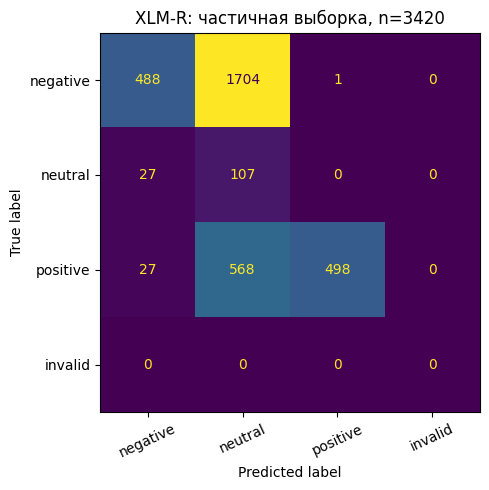

ВНИМАНИЕ: выборка состоит из первых завершённых батчей и может быть нерепрезентативной. Итоговые метрики предварительные.


In [9]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from IPython.display import display

LABELS_MVP = ["negative", "neutral", "positive"]
VALID_PREDICTIONS = set(LABELS_MVP) | {"invalid"}

MVP_DIR = Path("mvp_results")
MVP_DIR.mkdir(parents=True, exist_ok=True)

# Используем кэш остановленного расчёта.
if "cache_file" in globals() and Path(cache_file).is_file():
    CACHE_PATH = Path(cache_file)
else:
    candidates = sorted(MVP_DIR.glob("cache_*.jsonl"))

    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Найдено файлов кэша: {len(candidates)}. "
            "Нужно восстановить cache_file или указать CACHE_PATH."
        )

    CACHE_PATH = candidates[0]

# Проверяем, что данные из предыдущих ячеек доступны.
if (
    "reviews" not in globals()
    or "text_sha256" not in reviews
    or "expected" not in reviews
):
    raise RuntimeError(
        "Сначала запусти раздел загрузки данных, "
        "чтобы появилась таблица reviews."
    )

# Считываем все сохранённые предсказания модели.
saved = {}
bad_lines = 0

with CACHE_PATH.open("r", encoding="utf-8") as file:
    for line in file:
        if not line.strip():
            continue

        try:
            item = json.loads(line)

            if item["predicted"] not in VALID_PREDICTIONS:
                raise ValueError("Неизвестный класс")

            saved[item["key"]] = item

        except (ValueError, KeyError, TypeError):
            bad_lines += 1

# Берём только действительно обработанные отзывы.
result = reviews.loc[
    reviews["text_sha256"].isin(saved)
].copy()

if result.empty:
    raise ValueError("Нет обработанных отзывов в кэше.")

# Добавляем ответы XLM-R и оценки трёх классов.
result["predicted"] = result["text_sha256"].map(
    lambda key: saved[key]["predicted"]
)

for label in LABELS_MVP:
    field = f"score_{label}"

    result[field] = result["text_sha256"].map(
        lambda key: saved[key].get(field, np.nan)
    )

result["correct"] = (
    result["expected"].eq(result["predicted"])
    .where(result["expected"].isin(LABELS_MVP), pd.NA)
    .astype("boolean")
)

result.to_csv(
    MVP_DIR / "predictions_partial.csv",
    index=False,
    encoding="utf-8-sig"
)

# Метрики считаем только для строк с рейтингом 1–5.
valid = result[
    result["expected"].isin(LABELS_MVP)
].copy()

if valid.empty:
    raise ValueError("Нет отзывов с контрольными метками.")

y_true = valid["expected"]
y_pred = valid["predicted"]

# Базовый метод: всегда отвечать «негатив».
baseline = pd.Series(
    ["negative"] * len(valid),
    index=valid.index
)

# Подробные показатели качества модели.
report = classification_report(
    y_true,
    y_pred,
    labels=LABELS_MVP,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).T

report_df.to_csv(
    MVP_DIR / "classification_report_partial.csv",
    encoding="utf-8-sig"
)

def collect_metrics(name, predictions):
    details = classification_report(
        y_true,
        predictions,
        labels=LABELS_MVP,
        output_dict=True,
        zero_division=0
    )

    return {
        "model": name,
        "rows": len(valid),
        "accuracy": accuracy_score(y_true, predictions),
        "macro_f1": f1_score(
            y_true,
            predictions,
            labels=LABELS_MVP,
            average="macro",
            zero_division=0
        ),
        "balanced_accuracy_3_classes": np.mean([
            details[label]["recall"]
            for label in LABELS_MVP
        ])
    }

metrics = pd.DataFrame([
    collect_metrics("XLM-R (частичная выборка)", y_pred),
    collect_metrics("Всегда негатив (baseline)", baseline)
])

metrics.to_csv(
    MVP_DIR / "metrics_partial.csv",
    index=False,
    encoding="utf-8-sig"
)

# Проверяем, насколько частичная выборка похожа на полную.
class_dist = pd.DataFrame({
    "весь датасет": reviews["expected"].value_counts().reindex(
        LABELS_MVP, fill_value=0
    ),
    "обработанная часть": valid["expected"].value_counts().reindex(
        LABELS_MVP, fill_value=0
    )
})

class_dist["доля во всём файле"] = (
    class_dist["весь датасет"] / len(reviews)
)

class_dist["доля среди обработанных"] = (
    class_dist["обработанная часть"] / len(valid)
)

print(
    f"Обработано: {len(result)} из {len(reviews)} "
    f"({len(result) / len(reviews):.1%})"
)

print("Некорректных строк кэша:", bad_lines)

print("\nРаспределение классов:")
display(class_dist.round(3))

print("\nML-метрики:")
display(metrics.round(4))

print("\nPrecision, Recall и F1:")
display(report_df.round(4))

# Матрица ошибок.
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=LABELS_MVP + ["invalid"]
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    cm,
    display_labels=LABELS_MVP + ["invalid"]
).plot(
    ax=ax,
    colorbar=False,
    values_format="d"
)

ax.set_title(
    f"XLM-R: частичная выборка, n={len(valid)}"
)

plt.xticks(rotation=25)
fig.tight_layout()

fig.savefig(
    MVP_DIR / "confusion_matrix_partial.png",
    dpi=140
)
plt.show()

if len(result) < len(reviews):
    print(
        "ВНИМАНИЕ: выборка состоит из первых завершённых "
        "батчей и может быть нерепрезентативной. "
        "Итоговые метрики предварительные."
    )

# БИЗНЕС-МЕТРИКИ, FTE И ROI

In [12]:
# Предварительный порог неопределённости модели.
# Margin — разница между двумя максимальными оценками.
# Это НЕ калиброванная вероятность ошибки.
UNCERTAIN_MARGIN_MVP = 0.15

score_cols = [
    f"score_{label}" for label in LABELS_MVP
]

score_values = result[score_cols].apply(
    pd.to_numeric, errors="coerce"
).to_numpy(dtype=float)

sorted_scores = np.sort(score_values, axis=1)

result["margin"] = (
    sorted_scores[:, -1] - sorted_scores[:, -2]
)

# Правило маршрутизации отзывов сотруднику.
result["needs_manual_review"] = (
    result["predicted"].isin(["negative", "invalid"])
    | result["margin"].isna()
    | result["margin"].lt(UNCERTAIN_MARGIN_MVP)
)

result.to_csv(
    MVP_DIR / "predictions_partial.csv",
    index=False,
    encoding="utf-8-sig"
)

# Измеренные бизнес-показатели на обработанных данных.
valid = result[
    result["expected"].isin(LABELS_MVP)
].copy()

negative = valid["expected"].eq("negative")
flagged = valid["needs_manual_review"]

def safe_ratio(numerator, denominator):
    return (
        float(numerator / denominator)
        if denominator else np.nan
    )

# Доля отзывов для ручной проверки.
review_share = float(
    result["needs_manual_review"].mean()
)

# Доля отрицательных оценок, попавших на проверку.
negative_coverage = safe_ratio(
    (negative & flagged).sum(),
    negative.sum()
)

# Доля отрицательных оценок среди направленных на проверку.
negative_precision_in_queue = safe_ratio(
    (negative & flagged).sum(),
    flagged.sum()
)

# Негативные оценки, которые система пропустила.
missed_negative = int(
    (negative & ~flagged).sum()
)

# СЦЕНАРНАЯ ЭКОНОМИКА
# Все значения ниже — допущения

MONTHLY_REVIEWS = 10_000
MINUTES_BEFORE = 2.0
MINUTES_FLAGGED = 2.0
MINUTES_NOT_FLAGGED = 0.2

WORK_HOURS_PER_FTE = 160
COST_PER_FTE_RUB = 120_000

MONTHLY_MODEL_COST_RUB = 5_000
IMPLEMENTATION_COST_RUB = 75_000

# Рабочее время до внедрения ИИ.
hours_before = (
    MONTHLY_REVIEWS * MINUTES_BEFORE / 60
)

# Прогнозируемое время с ИИ.
hours_after = MONTHLY_REVIEWS * (
    review_share * MINUTES_FLAGGED
    + (1 - review_share) * MINUTES_NOT_FLAGGED
) / 60

# Потенциально высвобождаемое время.
hours_saved = hours_before - hours_after

# Эквивалент высвобожденной загрузки сотрудников.
fte_saved = hours_saved / WORK_HOURS_PER_FTE

# Денежный эквивалент высвобожденной загрузки.
monthly_capacity_value = (
    fte_saved * COST_PER_FTE_RUB
)

monthly_net_capacity_value = (
    monthly_capacity_value - MONTHLY_MODEL_COST_RUB
)

# Условный ROI за первый год.
roi_12m_pct = (
    (
        12 * monthly_net_capacity_value
        - IMPLEMENTATION_COST_RUB
    ) / IMPLEMENTATION_COST_RUB * 100
    if IMPLEMENTATION_COST_RUB > 0
    else np.nan
)

# Условный срок окупаемости.
payback_months = (
    IMPLEMENTATION_COST_RUB / monthly_net_capacity_value
    if monthly_net_capacity_value > 0
    else np.nan
)

business = pd.DataFrame([{
    "evaluated_rows": len(valid),
    "manual_review_share_measured": review_share,
    "negative_coverage_vs_star_rating": negative_coverage,
    "negative_share_among_flagged_vs_stars": negative_precision_in_queue,
    "missed_negative_in_processed_sample": missed_negative,
    "monthly_reviews_assumed": MONTHLY_REVIEWS,
    "hours_before_scenario": hours_before,
    "hours_after_scenario": hours_after,
    "hours_saved_scenario": hours_saved,
    "fte_saved_scenario": fte_saved,
    "monthly_capacity_value_rub_scenario": monthly_capacity_value,
    "net_monthly_value_rub_scenario": monthly_net_capacity_value,
    "roi_12m_percent_scenario": roi_12m_pct,
    "payback_months_scenario": payback_months
}])

business.to_csv(
    MVP_DIR / "business_metrics_scenario_partial.csv",
    index=False,
    encoding="utf-8-sig"
)

print("ИЗМЕРЕННЫЕ ПОКАЗАТЕЛИ НА ОБРАБОТАННОЙ ЧАСТИ:")

display(
    business[[
        "evaluated_rows",
        "manual_review_share_measured",
        "negative_coverage_vs_star_rating",
        "negative_share_among_flagged_vs_stars",
        "missed_negative_in_processed_sample"
    ]].T.rename(columns={0: "значение"}).round(4)
)

print("\nГИПОТЕТИЧЕСКАЯ ЭКОНОМИКА:")

display(
    business[[
        "fte_saved_scenario",
        "net_monthly_value_rub_scenario",
        "roi_12m_percent_scenario",
        "payback_months_scenario"
    ]].T.rename(columns={0: "значение"}).round(2)
)

ИЗМЕРЕННЫЕ ПОКАЗАТЕЛИ НА ОБРАБОТАННОЙ ЧАСТИ:


,значение
evaluated_rows,3420.0000
manual_review_share_measured,0.2816
negative_coverage_vs_star_rating,0.3238
negative_share_among_flagged_vs_stars,0.7373
missed_negative_in_processed_sample,1483.0000



ГИПОТЕТИЧЕСКАЯ ЭКОНОМИКА:


,значение
fte_saved_scenario,1.35
net_monthly_value_rub_scenario,156644.74
roi_12m_percent_scenario,2406.32
payback_months_scenario,0.48


# ПРОВЕРКА ЗАВЕРШЕНИЯ

In [13]:
all_keys = set(
    reviews["text_sha256"].astype(str)
)

finished_keys = all_keys.intersection(saved)

full_completed = (
    len(finished_keys) == len(all_keys)
)

status = {
    "dataset_rows": int(len(reviews)),
    "unique_texts": int(len(all_keys)),
    "processed_rows": int(len(result)),
    "processed_unique_texts": int(len(finished_keys)),
    "processed_share": float(
        len(result) / len(reviews)
    ),
    "labeled_rows_processed": int(len(valid)),
    "cache_file": str(CACHE_PATH),
    "full_completed": bool(full_completed),
    "results_are_partial": bool(not full_completed),
    "business_roi_is_assumption_based": True
}

status_file = MVP_DIR / "FINAL_STATUS_partial.json"

status_file.write_text(
    json.dumps(
        status,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("\nИТОГОВЫЙ СТАТУС MVP:")
print(
    json.dumps(
        status,
        ensure_ascii=False,
        indent=2
    )
)

print("\nРезультаты сохранены в:", MVP_DIR.resolve())

if not full_completed:
    print(
        "Обработка всего файла НЕ завершена. "
    )
else:
    print(
        "Обработаны все отзывы. "
        "Полный расчёт завершён."
    )


ИТОГОВЫЙ СТАТУС MVP:
{
  "dataset_rows": 12392,
  "unique_texts": 12392,
  "processed_rows": 3420,
  "processed_unique_texts": 3420,
  "processed_share": 0.275984506132989,
  "labeled_rows_processed": 3420,
  "cache_file": "mvp_results/cache_81029217c071a423.jsonl",
  "full_completed": false,
  "results_are_partial": true,
  "business_roi_is_assumption_based": true
}

Результаты сохранены в: /content/mvp_results
Обработка всего файла НЕ завершена. 
